# NYC Yellow Taxi (05/2026) — Business Understanding · Modeling · Evaluation

$$\boxed{\text{Business Understanding}} \rightarrow \text{Data Understanding} \rightarrow \text{Data Preparation} \rightarrow \boxed{\text{Modeling}} \rightarrow \boxed{\text{Evaluation}} \rightarrow \text{Deployment}$$

Notebook gộp 3 giai đoạn CRISP-DM. Data Understanding và Data Preparation ở notebook riêng.

**Quy ước nhãn:** **[BẰNG CHỨNG TỪ DỮ LIỆU]** = số tính ở cell ngay trên · **[GIẢ THUYẾT/SUY LUẬN]** = giải thích dữ liệu không chứng minh trực tiếp · **[GIẢ ĐỊNH KỊCH BẢN]** = tham số do nhóm đặt.

## Executive Summary

| # | Insight | Bằng chứng | Ai chịu tác động | Hành động |
|---|---|---|---|---|
| 1 | **Làm theo DM1, tài xế kiếm ít tiền hơn** | Top 20% ô theo DM1: **−2.66 USD/giờ có khách** (≈ −12.79 USD/ca), tip −0.48 USD/chuyến; điểm DM1 tương quan âm với tip USD (ρ = −0.41) – 4.1.5 | Tài xế | Không dùng DM1 để gợi ý khu vực |
| 2 | **Năng lực DM1 phần lớn đến từ lỗi dữ liệu** | 140,071 chuyến thẻ RatecodeID = 99 có tip = 0 ở 100%; loại ra: AUC **0.7164 → 0.6226**, giá trị **+2.93 → −0.04 USD/ca** – 4.1.2, 4.1.4 | Nền tảng | Sửa Data Preparation, lặp lại DM1 |
| 3 | **Lỗi dữ liệu → né sai khu dân cư** | Điểm DM1 gốc né **2,785 chuyến/ngày**, 73% ngoài Manhattan (Central Harlem North, Crown Heights North, East New York) – 4.1.5 | Khách khu dân cư | Không xếp hạng khu vực theo `high_tip` chưa sửa |
| 4 | **`high_tip` phạt sai chuyến đắt/sân bay** | Tip USD tăng 1.86 → 18.25 USD theo cước trong khi high_tip giảm 0.91 → 0.67; JFK tip TB **12.88 USD** nhưng high_tip 0.74 – 4.1.3, 4.2 | Tài xế | KPI tài xế = thu nhập/giờ + tip USD |
| 5 | **Tip do nút gợi ý quyết định** | **56.4%** chuyến tip đúng 20% tổng trước tip; không tip cao ở khu ăn chơi đêm cuối tuần (9.8–12.1%) – 4.3 | Khách, nền tảng | Minh bạch/thiết kế nút tip |
| 6 | **Thống kê lịch sử thắng model** | Top 20% ô theo thu nhập/giờ lịch sử: **+24.60 USD/giờ có khách** (51% chuyến chạm sân bay, chưa trừ hàng chờ) – 4.1.5 | Tài xế | Bảng KPI lịch sử theo ô + A/B test |
| 7 | **"Tip cao – ít xe" nội đô: lợi ích nhỏ** | +9.49 USD/giờ chỉ nhờ giả định chờ ít hơn (bỏ giả định: +0.01); hệ thống ≤ **1.47%** doanh thu – 4.4 | Tài xế, nền tảng | Thí điểm thưởng Midtown đêm, UES sáng cuối tuần |
| 8 | **DM2 dùng được cho điều phối** | Cụm sân bay (k=6): 8.5% chuyến – **23.9%** doanh thu, 55.5 phút/chuyến – 4.1.6 | Nền tảng | Thí điểm lịch điều phối theo cụm |

**Quyết định:** DM2 → Deployment thí điểm · bảng KPI zone × khung giờ → thí điểm có A/B test · DM1 → **lặp lại vòng CRISP-DM**.

## 1. Business Understanding

**Bối cảnh.** Yellow Taxi cạnh tranh với Uber/Lyft; chi phí vận hành gần như cố định → tối ưu thu nhập tài xế và điều phối xe là yếu tố sống còn. TLC công bố dữ liệu từng chuyến (giờ, zone, quãng đường, cước, tip thẻ).

**Vấn đề:** (1) tài xế chọn khu vực/khung giờ theo cảm tính; (2) điều phối không có công cụ định lượng → mất cân đối cung–cầu cục bộ.

| Bên liên quan | Cần gì | Mức ảnh hưởng |
|---|---|---|
| Tài xế | Nên chạy ở đâu, khi nào để tăng thu nhập | Cao |
| Điều phối / hãng taxi | Mẫu hình nhu cầu theo khu vực × khung giờ | Cao |
| Hành khách | Ít chờ xe hơn (gián tiếp) | Thấp |

| Mã | Mục tiêu nghiệp vụ | Bài toán mining | Biến mục tiêu / kỹ thuật |
|---|---|---|---|
| **BO1** | Hỗ trợ tài xế nhận diện khu vực/khung giờ/đặc điểm chuyến có khả năng tip cao | **DM1** – phân loại | `high_tip` = 1 nếu tip/fare ≥ 15% (chỉ chuyến thẻ); Logistic Regression vs HistGradientBoosting |
| **BO2** | Hỗ trợ điều phối xe theo mẫu hình nhu cầu | **DM2** – phân cụm | KMeans trên quãng đường, thời lượng, giờ/thứ (mã hoá chu kỳ), borough đón/trả |

**Tiêu chí thành công**

| Loại | Tiêu chí |
|---|---|
| Business | Kết quả chuyển được thành hành động cho tài xế/điều phối; giới hạn được nêu rõ |
| DM1 | AUC vượt rõ Dummy & baseline; không dùng Accuracy làm thước đo chính; diễn giải được yếu tố quan trọng |
| DM2 | Silhouette > 0.3; chọn k bằng chỉ số định lượng; đặt tên được từng cụm |

**Rủi ro & giới hạn đã biết trước:** tip tiền mặt không được ghi nhận → DM1 chỉ dùng chuyến thẻ · zone là vùng, không phải toạ độ · dữ liệu 1 tháng (không có mùa vụ) · không có ID xe/tài xế/khách.

## 2. Dữ liệu đầu vào

Chạy lại pipeline Data Preparation trên dữ liệu thô nhưng giữ thêm zone, tip, tổng tiền, thời điểm đón/trả (cần cho Evaluation), rồi **kiểm tra trùng khớp từng giá trị** với 2 file processed.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.cluster import MiniBatchKMeans
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, silhouette_score,
                             davies_bouldin_score, RocCurveDisplay, PrecisionRecallDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("whitegrid")
plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 10})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

RANDOM_STATE = 42
RAW_PATH = "data/raw/yellow_tripdata_2026-05.parquet"
ZONE_PATH = "data/raw/taxi_zone_lookup.csv"
DM1_PATH = "data/processed/classification_data.parquet"
DM2_PATH = "data/processed/clustering_data.parquet"

# Fixed categorical colour order (validated reference palette) - never cycled
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_MAGENTA, C_GREEN, C_VIOLET, C_RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
C_GREY = "#898781"
DIV_CMAP = LinearSegmentedColormap.from_list("orange_grey_blue", [C_ORANGE, "#f0efec", C_BLUE])

TOD_ORDER = ["early_morning", "midday", "peak_hour", "late_night"]
SLOT_ORDER = [f"{d}|{t}" for d in ["weekday", "weekend"] for t in TOD_ORDER]
AIRPORT_ZONE_IDS = [1, 132, 138]   # Newark, JFK, LaGuardia
UNKNOWN_ZONE_IDS = [264, 265]      # placeholder zones in the TLC lookup

In [2]:
def time_of_day(hour: pd.Series) -> np.ndarray:
    """Same 4 buckets as Data_Preparation."""
    return np.select(
        [(hour >= 6) & (hour < 10), (hour >= 10) & (hour < 16), (hour >= 16) & (hour < 20)],
        ["early_morning", "midday", "peak_hour"], default="late_night")


def slot_label(ts: pd.Series) -> pd.Series:
    """Day type x time_of_day, e.g. 'weekday|peak_hour' (8 slots)."""
    day_type = pd.Series(np.where(ts.dt.dayofweek >= 5, "weekend", "weekday"), index=ts.index)
    return day_type + "|" + pd.Series(time_of_day(ts.dt.hour), index=ts.index)


def build_clean_trips(raw_path: str, zone_path: str) -> pd.DataFrame:
    """Replicate the Data_Preparation pipeline, keeping zone/tip/total/timestamp columns."""
    df = pd.read_parquet(raw_path)
    df["ratecode_was_null"] = df["RatecodeID"].isna()
    df[["congestion_surcharge", "Airport_fee"]] = df[["congestion_surcharge", "Airport_fee"]].fillna(0)
    df["passenger_count"] = df["passenger_count"].fillna(df["passenger_count"].mode().iloc[0])
    df["store_and_fwd_flag"] = df["store_and_fwd_flag"].fillna(df["store_and_fwd_flag"].mode().iloc[0])
    df["RatecodeID"] = df["RatecodeID"].fillna(99)

    df = df[(df["fare_amount"] > 0) & (df["fare_amount"] < 500)
            & (df["trip_distance"] > 0) & (df["trip_distance"] < 100)
            & (df["passenger_count"] >= 1) & (df["passenger_count"] <= 6)
            & (df["tpep_dropoff_datetime"] > df["tpep_pickup_datetime"])
            & (df["VendorID"].isin([1, 2, 6, 7]))].copy()
    df["trip_duration_min"] = ((df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"])
                               .dt.total_seconds() / 60.0).round(1)
    df = df[(df["trip_duration_min"] >= 1) & (df["trip_duration_min"] <= 180)]
    df = df[df["trip_distance"] / df["trip_duration_min"] * 60 <= 65].copy()

    ts = df["tpep_pickup_datetime"]
    df["pickup_hour"] = ts.dt.hour
    df["pickup_dayofweek"] = ts.dt.dayofweek
    df["is_weekend"] = df["pickup_dayofweek"].isin([5, 6]).astype(int)
    df["time_of_day"] = time_of_day(df["pickup_hour"])
    df["tip_percentage"] = np.where(df["fare_amount"] > 0, df["tip_amount"] / df["fare_amount"], 0)
    df["high_tip"] = (df["tip_percentage"] >= 0.15).astype(int)

    zones = pd.read_csv(zone_path)
    for side, key in [("pickup", "PULocationID"), ("dropoff", "DOLocationID")]:
        lookup = zones.rename(columns={"LocationID": key, "Borough": f"{side}_borough", "Zone": f"{side}_zone"})
        df = df.merge(lookup[[key, f"{side}_borough", f"{side}_zone"]], on=key, how="left")
    return df.reset_index(drop=True)


trips = build_clean_trips(RAW_PATH, ZONE_PATH)
dm1_processed = pd.read_parquet(DM1_PATH)
dm2_processed = pd.read_parquet(DM2_PATH)
pd.testing.assert_frame_equal(
    trips.loc[trips["payment_type"] == 1, dm1_processed.columns].reset_index(drop=True),
    dm1_processed.reset_index(drop=True), check_dtype=False)
pd.testing.assert_frame_equal(trips[dm2_processed.columns].reset_index(drop=True),
                              dm2_processed.reset_index(drop=True), check_dtype=False)
print(f"OK - {len(trips):,} trips identical to clustering_data.parquet; "
      f"{len(dm1_processed):,} card trips identical to classification_data.parquet")

OK - 3,886,428 trips identical to clustering_data.parquet; 2,643,757 card trips identical to classification_data.parquet


In [3]:
for c in ["pickup_borough", "dropoff_borough"]:
    trips[c] = trips[c].fillna("Outside_NYC")

trips["slot"] = slot_label(trips["tpep_pickup_datetime"])
trips["dropoff_slot"] = slot_label(trips["tpep_dropoff_datetime"])
trips["is_card"] = trips["payment_type"] == 1
trips["is_cash"] = trips["payment_type"] == 2
trips["is_r99"] = (trips["RatecodeID"] == 99) & ~trips["ratecode_was_null"]   # recorded 99, not a filled null
trips["card_ok"] = trips["is_card"] & ~trips["is_r99"]                         # analysis set for tip behaviour
trips["zero_tip"] = trips["tip_amount"] == 0
trips["revenue"] = trips["fare_amount"] + trips["tip_amount"]                  # driver income proxy (card tips only)
trips["speed_mph"] = trips["trip_distance"] / trips["trip_duration_min"] * 60
trips["is_airport"] = trips["PULocationID"].isin(AIRPORT_ZONE_IDS) | trips["DOLocationID"].isin(AIRPORT_ZONE_IDS)
trips["has_airport_fee"] = trips["Airport_fee"] > 0                            # charged only on LGA/JFK pickups
trips["pu_in_month"] = trips["tpep_pickup_datetime"].dt.year.eq(2026) & trips["tpep_pickup_datetime"].dt.month.eq(5)
trips["do_in_month"] = trips["tpep_dropoff_datetime"].dt.year.eq(2026) & trips["tpep_dropoff_datetime"].dt.month.eq(5)

zone_src = trips[trips["pu_in_month"] & ~trips["PULocationID"].isin(UNKNOWN_ZONE_IDS)]
N_DAYS = 31

print(pd.Series({
    "all clean trips": len(trips),
    "card trips (DM1)": int(trips["is_card"].sum()),
    "  card with recorded RatecodeID=99": int((trips["is_card"] & trips["is_r99"]).sum()),
    "card_ok": int(trips["card_ok"].sum()),
    "payment_type=0 (not reported)": int((trips["payment_type"] == 0).sum()),
}).to_string())
print("\nShare of trips with tip > 0 by payment type:",
      (1 - trips.groupby("payment_type")["zero_tip"].mean()).round(4).to_dict())

all clean trips                       3886428
card trips (DM1)                      2643757
  card with recorded RatecodeID=99     140071
card_ok                               2503686
payment_type=0 (not reported)          877060

Share of trips with tip > 0 by payment type: {0: 0.0942, 1: 0.9019, 2: 0.0001, 3: 0.0003, 4: 0.0002}


**[BẰNG CHỨNG TỪ DỮ LIỆU]** 3,886,428 chuyến (DM2), 2,643,757 chuyến thẻ (DM1), trùng khớp 100% file processed. Tip > 0: thẻ **90.19%**, tiền mặt **0.01%** → chỉ phân tích tip trên chuyến thẻ. **140,071** chuyến thẻ có `RatecodeID = 99` (xem 4.1.4) → tập phân tích tip `card_ok` = 2,503,686.

## 3. Modeling

### 3.1. DM1 – phân loại `high_tip`

Test design: train/test 80/20, `stratify` theo nhãn, `random_state = 42`. Đặc trưng thêm: `speed_mph`, `fare_per_mile`, `fare_per_min`, `hour_sin/cos`, `same_borough`. Ba model: **Dummy** (luôn đoán lớp đa số) · **Logistic Regression** (baseline) · **HistGradientBoosting** (best).

In [4]:
def engineer_dm1(X: pd.DataFrame) -> pd.DataFrame:
    X = X.copy()
    X["speed_mph"] = (X["trip_distance"] / X["trip_duration_min"] * 60).clip(0, 80)
    X["fare_per_mile"] = (X["fare_amount"] / X["trip_distance"].replace(0, np.nan)).fillna(0).clip(0, 100)
    X["fare_per_min"] = (X["fare_amount"] / X["trip_duration_min"]).clip(0, 50)
    X["hour_sin"] = np.sin(2 * np.pi * X["pickup_hour"] / 24)
    X["hour_cos"] = np.cos(2 * np.pi * X["pickup_hour"] / 24)
    X["same_borough"] = (X["pickup_borough"] == X["dropoff_borough"]).astype(int)
    return X


BASE_COLS = list(dm1_processed.columns.drop("high_tip"))
NUM_COLS = ["trip_distance", "trip_duration_min", "passenger_count", "pickup_hour", "pickup_dayofweek", "is_weekend",
            "fare_amount", "speed_mph", "fare_per_mile", "fare_per_min", "hour_sin", "hour_cos", "same_borough"]
CAT_COLS = ["time_of_day", "pickup_borough", "dropoff_borough"]

dm1 = trips[trips["is_card"]].reset_index(drop=True)
y1 = dm1["high_tip"]
idx_train, idx_test = train_test_split(np.arange(len(dm1)), test_size=0.2, stratify=y1, random_state=RANDOM_STATE)
X1_train, X1_test = engineer_dm1(dm1.loc[idx_train, BASE_COLS]), engineer_dm1(dm1.loc[idx_test, BASE_COLS])
y1_train, y1_test = y1.loc[idx_train], y1.loc[idx_test]
test_meta = dm1.loc[idx_test].copy()

dummy = DummyClassifier(strategy="most_frequent").fit(X1_train, y1_train)

t0 = time.time()
lr_pipe = Pipeline([
    ("pre", ColumnTransformer([("num", StandardScaler(), NUM_COLS),
                               ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)])),
    ("clf", LogisticRegression(max_iter=500, random_state=RANDOM_STATE)),
]).fit(X1_train, y1_train)
lr_time = time.time() - t0

ordenc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X1_train_enc, X1_test_enc = X1_train.copy(), X1_test.copy()
X1_train_enc[CAT_COLS] = ordenc.fit_transform(X1_train[CAT_COLS])
X1_test_enc[CAT_COLS] = ordenc.transform(X1_test[CAT_COLS])
t0 = time.time()
hgb = HistGradientBoostingClassifier(
    categorical_features=[X1_train_enc.columns.get_loc(c) for c in CAT_COLS],
    learning_rate=0.05, max_iter=500, max_leaf_nodes=63, l2_regularization=0.1, random_state=RANDOM_STATE,
).fit(X1_train_enc, y1_train)
hgb_time = time.time() - t0

p_dummy = dummy.predict_proba(X1_test)[:, 1]
p_lr = lr_pipe.predict_proba(X1_test)[:, 1]
p_hgb = hgb.predict_proba(X1_test_enc)[:, 1]
test_meta["p_hgb"] = p_hgb


def clf_report(name, prob, fit_time):
    pred = (prob >= 0.5).astype(int)
    return {"model": name, "fit_time_s": fit_time, "AUC": roc_auc_score(y1_test, prob),
            "PR_AUC": average_precision_score(y1_test, prob), "Accuracy": accuracy_score(y1_test, pred),
            "Precision": precision_score(y1_test, pred), "Recall": recall_score(y1_test, pred),
            "F1": f1_score(y1_test, pred), "Recall_low_tip": recall_score(y1_test, pred, pos_label=0)}


results_dm1 = pd.DataFrame([clf_report("Dummy (majority)", p_dummy, 0.0),
                            clf_report("Baseline - Logistic Regression", p_lr, lr_time),
                            clf_report("Best - HistGradientBoosting", p_hgb, hgb_time)])
print(f"Train {len(idx_train):,} | Test {len(idx_test):,} | high_tip share = {y1.mean():.4f}")
print(results_dm1.round(4).to_string(index=False))

Train 2,115,005 | Test 528,752 | high_tip share = 0.7877
                         model  fit_time_s    AUC  PR_AUC  Accuracy  Precision  Recall     F1  Recall_low_tip
              Dummy (majority)      0.0000 0.5000  0.7877    0.7877     0.7877  1.0000 0.8813          0.0000
Baseline - Logistic Regression     27.9007 0.6825  0.8649    0.8231     0.8228  0.9883 0.8980          0.2104
   Best - HistGradientBoosting    187.2395 0.7164  0.8872    0.8384     0.8310  0.9978 0.9068          0.2471


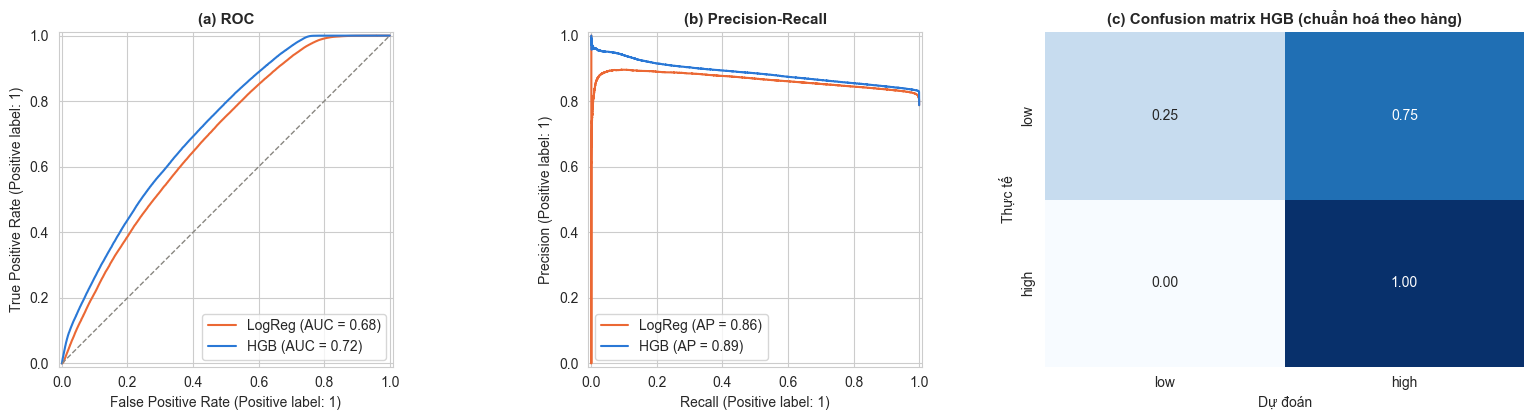

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for prob, name, c in [(p_lr, "LogReg", C_ORANGE), (p_hgb, "HGB", C_BLUE)]:
    RocCurveDisplay.from_predictions(y1_test, prob, name=name, ax=axes[0], color=c)
    PrecisionRecallDisplay.from_predictions(y1_test, prob, name=name, ax=axes[1], color=c)
axes[0].plot([0, 1], [0, 1], ls="--", lw=1, color=C_GREY)
axes[0].set_title("(a) ROC")
axes[1].set_title("(b) Precision-Recall")
cm = confusion_matrix(y1_test, (p_hgb >= 0.5).astype(int), normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=axes[2],
            xticklabels=["low", "high"], yticklabels=["low", "high"])
axes[2].set_title("(c) Confusion matrix HGB (chuẩn hoá theo hàng)")
axes[2].set_xlabel("Dự đoán")
axes[2].set_ylabel("Thực tế")
plt.tight_layout()
plt.show()

**[BẰNG CHỨNG TỪ DỮ LIỆU]** high_tip chiếm **78.77%** → Dummy đạt Accuracy 0.7877 dù AUC 0.5 → không dùng Accuracy.

| | AUC | PR-AUC | Recall low_tip | Thời gian train |
|---|---|---|---|---|
| Dummy | 0.5000 | 0.7877 | 0.0000 | – |
| LogReg | 0.6825 | 0.8649 | 0.2104 | 28 s |
| **HGB** | **0.7164** | **0.8872** | **0.2471** | 187 s |

HGB hơn LogReg **+0.034 AUC** nhưng chỉ nhận đúng **25%** chuyến tip thấp (confusion matrix). `class_weight="balanced"` (thử ở Modeling cũ) không đổi AUC, chỉ dịch điểm vận hành — tương đương chỉnh ngưỡng ở 4.1.2.

### 3.2. DM2 – phân cụm mẫu hình chuyến đi

Mẫu 200,000 chuyến (Silhouette có độ phức tạp bậc hai). **Baseline:** KMeans trên 5 biến số thô. **Best:** thêm mã hoá chu kỳ giờ/thứ + one-hot borough đón/trả. Quét k bằng Silhouette và Davies-Bouldin.

In [6]:
DM2_COLS = list(dm2_processed.columns)
NUM_BASE = ["trip_distance", "trip_duration_min", "pickup_hour", "pickup_dayofweek", "is_weekend"]
NUM_BEST = ["trip_distance", "trip_duration_min", "hour_sin", "hour_cos", "dow_sin", "dow_cos", "is_weekend"]
CAT_BEST = ["pickup_borough", "dropoff_borough"]


def add_cyclical(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["hour_sin"] = np.sin(2 * np.pi * out["pickup_hour"] / 24)
    out["hour_cos"] = np.cos(2 * np.pi * out["pickup_hour"] / 24)
    out["dow_sin"] = np.sin(2 * np.pi * out["pickup_dayofweek"] / 7)
    out["dow_cos"] = np.cos(2 * np.pi * out["pickup_dayofweek"] / 7)
    return out


def kmeans(k, X):
    return MiniBatchKMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10, batch_size=4096).fit(X)


samp2 = add_cyclical(trips[DM2_COLS].sample(200000, random_state=RANDOM_STATE).reset_index(drop=True))
X_base = ColumnTransformer([("num", StandardScaler(), NUM_BASE)]).fit_transform(samp2)
best_pre = ColumnTransformer([("num", StandardScaler(), NUM_BEST),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_BEST)])
X_best = best_pre.fit_transform(samp2)
X_best_dense = X_best.toarray() if hasattr(X_best, "toarray") else X_best

scan = []
for k in range(3, 9):
    row = {"k": k}
    if k <= 7:
        row["silhouette_baseline"] = silhouette_score(X_base, kmeans(k, X_base).labels_, sample_size=25000,
                                                      random_state=RANDOM_STATE)
    m = kmeans(k, X_best)
    row["silhouette_best"] = silhouette_score(X_best, m.labels_, sample_size=25000, random_state=RANDOM_STATE)
    row["dbi_best"] = davies_bouldin_score(X_best_dense, m.labels_)
    scan.append(row)
scan = pd.DataFrame(scan).set_index("k")
print(scan.round(4).to_string())

km = {k: kmeans(k, X_best) for k in (5, 6)}
X2_all = best_pre.transform(add_cyclical(trips[DM2_COLS]))
for k, m in km.items():
    trips[f"cluster_k{k}"] = m.predict(X2_all)

CLUSTER_NAMES_K5 = {0: "Ngắn – tan tầm ngày thường", 1: "Ngắn – trưa cuối tuần", 2: "Trung bình – cuối tuần",
                    3: "Dài/liên borough – ngày thường", 4: "Ngắn điển hình – ngày thường"}
g = trips.groupby("cluster_k5")
profile_k5 = pd.DataFrame({
    "name": pd.Series(CLUSTER_NAMES_K5), "share_trips": g.size() / len(trips),
    "avg_distance": g["trip_distance"].mean(), "avg_duration": g["trip_duration_min"].mean(),
    "avg_pickup_hour": g["pickup_hour"].mean(), "weekend_share": g["is_weekend"].mean(),
    "pickup_manhattan": g["pickup_borough"].apply(lambda s: (s == "Manhattan").mean()),
    "dropoff_outside_manhattan": g["dropoff_borough"].apply(lambda s: (s != "Manhattan").mean()),
})
print("\nk=5 profile on all trips:\n", profile_k5.to_string())

   silhouette_baseline  silhouette_best  dbi_best
k                                                
3               0.4302           0.2373    1.8242
4               0.3287           0.2251    1.6531
5               0.3222           0.2054    1.7488
6               0.2884           0.2416    1.4203
7               0.3267           0.2422    1.3413
8                  NaN           0.2410    1.5881



k=5 profile on all trips:
                              name  share_trips  avg_distance  avg_duration  avg_pickup_hour  weekend_share  pickup_manhattan  dropoff_outside_manhattan
0      Ngắn – tan tầm ngày thường       0.2034        2.3463       14.1986          17.7665         0.0000            0.9353                     0.0824
1           Ngắn – trưa cuối tuần       0.1369        2.9592       15.6571          12.1120         1.0000            0.8899                     0.1189
2          Trung bình – cuối tuần       0.1783        3.8879       17.9910          14.1728         1.0000            0.8453                     0.1510
3  Dài/liên borough – ngày thường       0.1947        6.0468       30.1218          10.7760         0.0099            0.7260                     0.2275
4    Ngắn điển hình – ngày thường       0.2867        2.6864       16.5965          14.6682         0.0000            0.9140                     0.1002


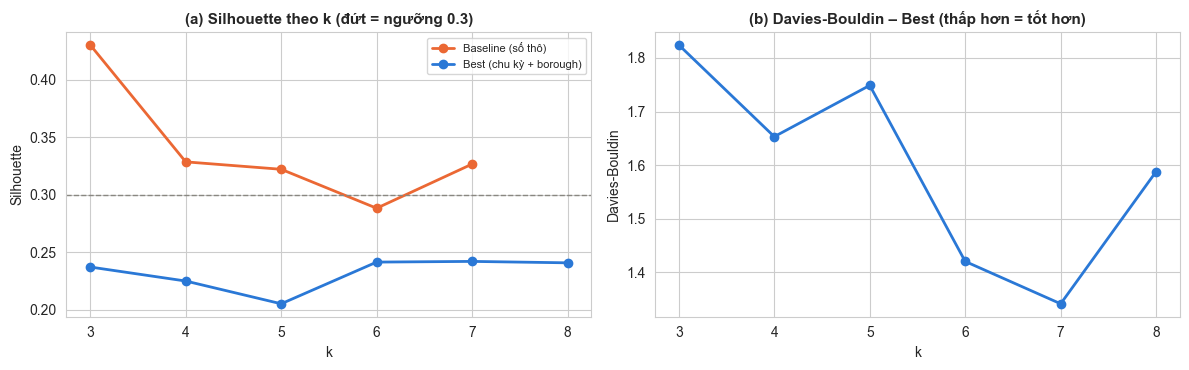

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(scan.index, scan["silhouette_baseline"], marker="o", lw=2, color=C_ORANGE, label="Baseline (số thô)")
axes[0].plot(scan.index, scan["silhouette_best"], marker="o", lw=2, color=C_BLUE, label="Best (chu kỳ + borough)")
axes[0].axhline(0.3, ls="--", lw=1, color=C_GREY)
axes[0].set_title("(a) Silhouette theo k (đứt = ngưỡng 0.3)")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Silhouette")
axes[0].legend(fontsize=8)
axes[1].plot(scan.index, scan["dbi_best"], marker="o", lw=2, color=C_BLUE)
axes[1].set_title("(b) Davies-Bouldin – Best (thấp hơn = tốt hơn)")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Davies-Bouldin")
plt.tight_layout()
plt.show()

**[BẰNG CHỨNG TỪ DỮ LIỆU]**
- Baseline đạt Silhouette cao nhất **0.4302** (k=3) nhưng chỉ tách "chuyến ngắn/dài" — không có thông tin không gian.
- Best: Silhouette cao nhất **0.2422** (k=7), DBI tốt nhất 1.3413 (k=7); k=6 gần như ngang (0.2416 / 1.4203). Chọn **k=5** (0.2054) vì dễ đặt tên; k=6 dùng để so sánh ở 4.1.6.
- 5 cụm (k=5): tan tầm ngày thường (20.3%, 17.8h), trưa cuối tuần (13.7%), trung bình cuối tuần (17.8%), **dài/liên borough ngày thường** (19.5%, 6.05 dặm, 30.1 phút, 22.8% trả khách ngoài Manhattan), ngắn điển hình ngày thường (28.7%).
- Silhouette best **< 0.3** → chưa đạt tiêu chí DM2.

## 4. Evaluation

KPI cho tài xế: **thu nhập/giờ có khách** (fare + tip thẻ) và **tip USD/chuyến**. `high_tip` chỉ dùng để chấm DM1. Giới hạn: tip tiền mặt không được ghi nhận; "cung" chỉ là proxy từ dòng chảy chuyến đi.

### 4.1. Đánh giá model theo mục tiêu business

#### 4.1.1. DM1: precision/recall từng lớp, lift & gain theo decile

Base rate high_tip (test) = 0.7877
   class  precision  recall
high_tip     0.8310  0.9978
 low_tip     0.9675  0.2471

HGB high_tip deciles:
 decile       1      2      3      4      5      6      7      8      9      10
rate     0.9341 0.8873 0.8743 0.8604 0.8406 0.8147 0.7966 0.7828 0.7534 0.3329
lift     1.1859 1.1264 1.1100 1.0923 1.0671 1.0343 1.0113 0.9938 0.9564 0.4226
cum_gain 0.1186 0.2312 0.3422 0.4514 0.5582 0.6616 0.7627 0.8621 0.9577 1.0000

HGB low_tip deciles (decile 1 = lowest P(high)):
 decile        1      2      3      4      5      6      7      8      9      10
rate      0.6671 0.2466 0.2172 0.2034 0.1853 0.1594 0.1396 0.1257 0.1127 0.0659
lift      3.1427 1.1616 1.0230 0.9580 0.8727 0.7509 0.6577 0.5919 0.5311 0.3104
cum_gain  0.3143 0.4304 0.5327 0.6285 0.7158 0.7909 0.8567 0.9159 0.9690 1.0000
share_r99 0.5247 0.0032 0.0018 0.0007 0.0006 0.0004 0.0001 0.0001 0.0001 0.0000


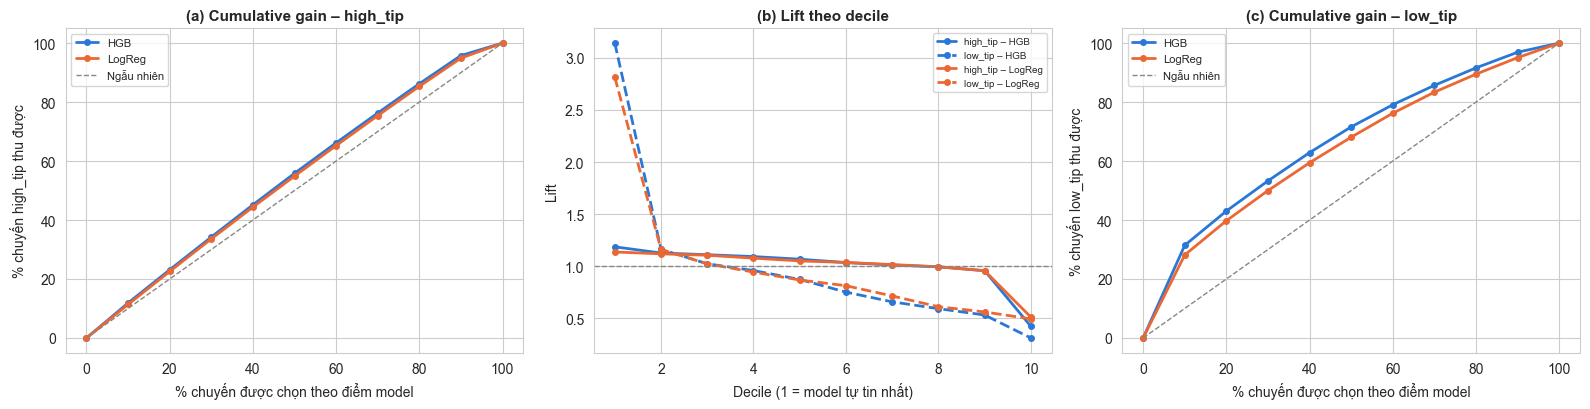

In [8]:
pred_hgb = (p_hgb >= 0.5).astype(int)
y_test_arr = y1_test.values
r99_flag = test_meta["is_r99"].values


def decile_table(y, score, extra=None):
    """Rank by score (highest first), 10 equal deciles."""
    d = pd.DataFrame({"y": np.asarray(y), "score": np.asarray(score)})
    for name, values in (extra or {}).items():
        d[name] = np.asarray(values)
    d["decile"] = pd.qcut(d["score"].rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int)
    agg = {"n": ("y", "size"), "positives": ("y", "sum")}
    agg.update({f"share_{name}": (name, "mean") for name in (extra or {})})
    t = d.groupby("decile").agg(**agg)
    t["rate"] = t["positives"] / t["n"]
    t["lift"] = t["rate"] / d["y"].mean()
    t["cum_gain"] = t["positives"].cumsum() / d["y"].sum()
    return t


per_class = pd.DataFrame([{"class": name, "precision": precision_score(y1_test, pred_hgb, pos_label=lab),
                           "recall": recall_score(y1_test, pred_hgb, pos_label=lab)}
                          for name, lab in [("high_tip", 1), ("low_tip", 0)]])
dec_high = {"HGB": decile_table(y1_test, p_hgb), "LogReg": decile_table(y1_test, p_lr)}
dec_low = {"HGB": decile_table(1 - y1_test, 1 - p_hgb, extra={"r99": r99_flag}),
           "LogReg": decile_table(1 - y1_test, 1 - p_lr)}
print(f"Base rate high_tip (test) = {y1_test.mean():.4f}")
print(per_class.round(4).to_string(index=False))
print("\nHGB high_tip deciles:\n", dec_high["HGB"][["rate", "lift", "cum_gain"]].T.round(4).to_string())
print("\nHGB low_tip deciles (decile 1 = lowest P(high)):\n",
      dec_low["HGB"][["rate", "lift", "cum_gain", "share_r99"]].T.round(4).to_string())

x_pct = np.arange(0, 101, 10)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for name, c in [("HGB", C_BLUE), ("LogReg", C_ORANGE)]:
    axes[0].plot(x_pct, np.r_[0, dec_high[name]["cum_gain"] * 100], marker="o", ms=4, lw=2, color=c, label=name)
    axes[1].plot(range(1, 11), dec_high[name]["lift"], marker="o", ms=4, lw=2, color=c, label=f"high_tip – {name}")
    axes[1].plot(range(1, 11), dec_low[name]["lift"], marker="o", ms=4, lw=2, ls="--", color=c, label=f"low_tip – {name}")
    axes[2].plot(x_pct, np.r_[0, dec_low[name]["cum_gain"] * 100], marker="o", ms=4, lw=2, color=c, label=name)
for ax in (axes[0], axes[2]):
    ax.plot([0, 100], [0, 100], ls="--", lw=1, color=C_GREY, label="Ngẫu nhiên")
    ax.set_xlabel("% chuyến được chọn theo điểm model")
    ax.legend(fontsize=8)
axes[0].set_title("(a) Cumulative gain – high_tip")
axes[0].set_ylabel("% chuyến high_tip thu được")
axes[1].axhline(1, ls="--", lw=1, color=C_GREY)
axes[1].set_title("(b) Lift theo decile")
axes[1].set_xlabel("Decile (1 = model tự tin nhất)")
axes[1].set_ylabel("Lift")
axes[1].legend(fontsize=7)
axes[2].set_title("(c) Cumulative gain – low_tip")
axes[2].set_ylabel("% chuyến low_tip thu được")
plt.tight_layout()
plt.show()

**Insight:** DM1 gần như không giúp tìm chuyến tip cao; giá trị chỉ nằm ở 10% chuyến bị chấm thấp nhất — và một nửa trong đó là artifact.

**[BẰNG CHỨNG TỪ DỮ LIỆU]**
- Precision high_tip **0.8310** vs tỷ lệ nền 0.7877 (+4.3 điểm). Top 30% điểm cao gom **34.2%** chuyến high_tip (ngẫu nhiên: 30%).
- Low_tip decile 1: lift **3.14**, gom **31.4%** chuyến tip thấp — nhưng **52.5%** decile này là RatecodeID = 99; từ decile 2 lift chỉ 1.16.

**Tác động:** nhãn "tip cao" của DM1 gần như vô giá trị với tài xế; "cảnh báo tip thấp" chủ yếu bắt lỗi dữ liệu.

#### 4.1.2. Chi phí của việc đoán sai

| Lỗi | Tài xế | Nền tảng |
|---|---|---|
| **FN – bỏ sót tip cao** | Bỏ lỡ khu/khung giờ đáng chạy | Phân bổ xe kém tối ưu |
| **FP – báo nhầm** | Chạy tới nơi được "hứa" tip cao nhưng không được, mất niềm tin | Trả thưởng khu vực sai chỗ |

**[GIẢ ĐỊNH KỊCH BẢN]** mỗi lỗi = chênh lệch tip TB giữa chuyến high và low (đo trên test) × hệ số FN:FP ∈ {1:2, 1:1, 2:1}; ca 8h, 60% thời gian có khách.

TIP_GAP = 3.80 USD | @0.5: FP = 84,506, FN = 932 | trips/shift [assumption] = 15.2
Cost per 1,000 trips (USD):
    scenario  best_threshold  cost_best  cost_at_0.5
FN:FP = 1:2          0.6500   607.6500     610.6200
FN:FP = 1:1          0.5000   613.9700     613.9700
FN:FP = 2:1          0.4000   618.6400     620.6600

DM1 saving vs no model (USD per driver shift):
             subset  saving_per_shift
      Toàn bộ test            2.9300
Loại RatecodeID=99           -0.0400


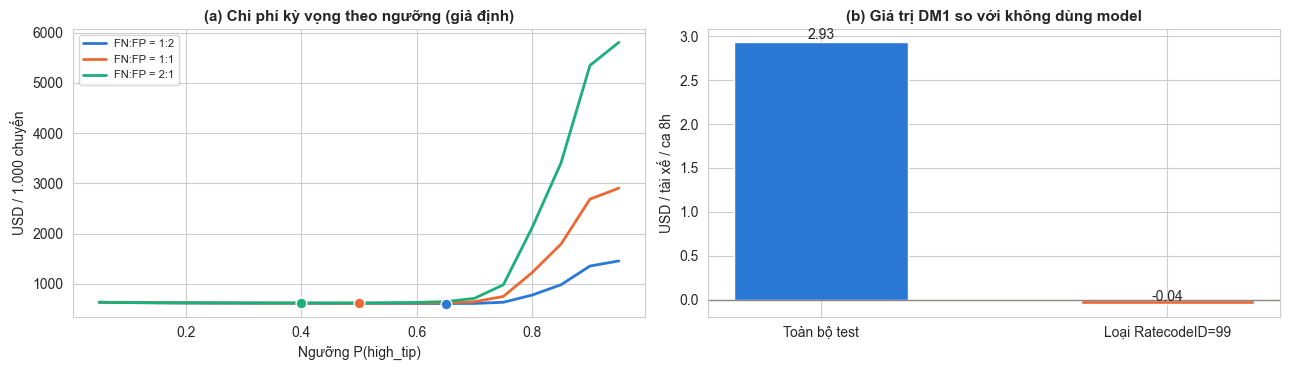

In [9]:
TIP_GAP = (test_meta.loc[y_test_arr == 1, "tip_amount"].mean() - test_meta.loc[y_test_arr == 0, "tip_amount"].mean())
SHIFT_H, UTIL = 8, 0.6
trips_per_shift = SHIFT_H * 60 * UTIL / test_meta["trip_duration_min"].mean()
COST_RATIOS = {"FN:FP = 1:2": 0.5, "FN:FP = 1:1": 1.0, "FN:FP = 2:1": 2.0}

rows = []
for t in np.round(np.arange(0.05, 0.96, 0.05), 2):
    tn, fp, fn, tp = confusion_matrix(y1_test, (p_hgb >= t).astype(int)).ravel()
    rows.append({"threshold": t, "FP": fp, "FN": fn,
                 **{name: (fp + r * fn) * TIP_GAP / len(y1_test) * 1000 for name, r in COST_RATIOS.items()}})
sweep = pd.DataFrame(rows)
best_thr = pd.DataFrame([{"scenario": n, "best_threshold": sweep.loc[sweep[n].idxmin(), "threshold"],
                          "cost_best": sweep[n].min(),
                          "cost_at_0.5": sweep.loc[np.isclose(sweep["threshold"], 0.5), n].iloc[0]}
                         for n in COST_RATIOS])


def error_cost_per_trip(y, pred):
    return (((pred == 1) & (y == 0)).sum() + ((pred == 0) & (y == 1)).sum()) * TIP_GAP / len(y)


value_tbl = pd.DataFrame([
    {"subset": name, "saving_per_shift": (error_cost_per_trip(y_test_arr[m], np.ones(m.sum(), int))
                                          - error_cost_per_trip(y_test_arr[m], pred_hgb[m])) * trips_per_shift}
    for name, m in [("Toàn bộ test", np.ones(len(y_test_arr), bool)), ("Loại RatecodeID=99", ~r99_flag)]])
tn, fp, fn, tp = confusion_matrix(y1_test, pred_hgb).ravel()
print(f"TIP_GAP = {TIP_GAP:.2f} USD | @0.5: FP = {fp:,}, FN = {fn:,} | trips/shift [assumption] = {trips_per_shift:.1f}")
print("Cost per 1,000 trips (USD):\n", best_thr.round(2).to_string(index=False))
print("\nDM1 saving vs no model (USD per driver shift):\n", value_tbl.round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for (name, _), c in zip(COST_RATIOS.items(), [C_BLUE, C_ORANGE, C_AQUA]):
    axes[0].plot(sweep["threshold"], sweep[name], lw=2, color=c, label=name)
    i = sweep[name].idxmin()
    axes[0].scatter(sweep.loc[i, "threshold"], sweep.loc[i, name], s=60, color=c, edgecolor="white", zorder=3)
axes[0].set_title("(a) Chi phí kỳ vọng theo ngưỡng (giả định)")
axes[0].set_xlabel("Ngưỡng P(high_tip)")
axes[0].set_ylabel("USD / 1.000 chuyến")
axes[0].legend(fontsize=8)
axes[1].bar(value_tbl["subset"], value_tbl["saving_per_shift"], color=[C_BLUE, C_ORANGE], width=0.5)
for i, v in enumerate(value_tbl["saving_per_shift"]):
    axes[1].text(i, v, f"{v:.2f}", ha="center", va="bottom")
axes[1].axhline(0, color=C_GREY, lw=1)
axes[1].set_title("(b) Giá trị DM1 so với không dùng model")
axes[1].set_ylabel(f"USD / tài xế / ca {SHIFT_H}h")
plt.tight_layout()
plt.show()

**Insight:** chỉnh ngưỡng không tạo giá trị; khi loại artifact, DM1 không tiết kiệm được gì.

**[BẰNG CHỨNG TỪ DỮ LIỆU + GIẢ ĐỊNH]**
- Mỗi lỗi = **3.80 USD**. Ngưỡng 0.5: **84,506 FP** vs **932 FN** → model gần như luôn nói "tip cao"; chi phí bị chi phối bởi **báo nhầm**.
- Đổi FN:FP từ 1:2 → 2:1: ngưỡng tối ưu 0.65 → 0.40, chi phí giảm **< 0.5%** (607.65–618.64 USD/1.000 chuyến).
- Giá trị DM1 so với không dùng model (15.2 chuyến/ca): **+2.93 USD/ca**, nhưng **−0.04 USD/ca** khi loại RatecodeID = 99.

**Tác động:** tài xế không được lợi; nền tảng gắn thưởng theo dự đoán từng chuyến sẽ trả sai chỗ.

#### 4.1.3. Yếu tố nào thúc đẩy `high_tip`?

Permutation importance **theo nhóm yếu tố** (xáo đồng thời các biến cùng nhóm, tránh bị che bởi biến tương quan) + kiểm tra cơ chế nhãn: `fare` nằm ở mẫu số của `high_tip`.

Grouped AUC drop:
 Giá cước                   0.2044
Quãng đường & thời lượng   0.0193
Thời gian (giờ, thứ)       0.0158
Khu vực (borough)          0.0148
Số hành khách              0.0004

Top single features:
 fare_amount         0.1541
fare_per_min        0.0285
fare_per_mile       0.0153
trip_duration_min   0.0151
trip_distance       0.0080
pickup_hour         0.0075



              mean_tip_usd  high_tip_rate  zero_tip_share
fare_amount                                             
(0, 5]             1.8617         0.9089          0.0786
(5, 8]             2.1947         0.9019          0.0486
(8, 10]            2.6197         0.8692          0.0455
(10, 15]           3.1973         0.8344          0.0438
(15, 20]           4.0241         0.7993          0.0452
(20, 30]           5.1956         0.7823          0.0478
(30, 50]           8.5057         0.8013          0.0490
(50, 80]          13.5099         0.7766          0.0550
(80, 500]         18.2500         0.6739          0.1117


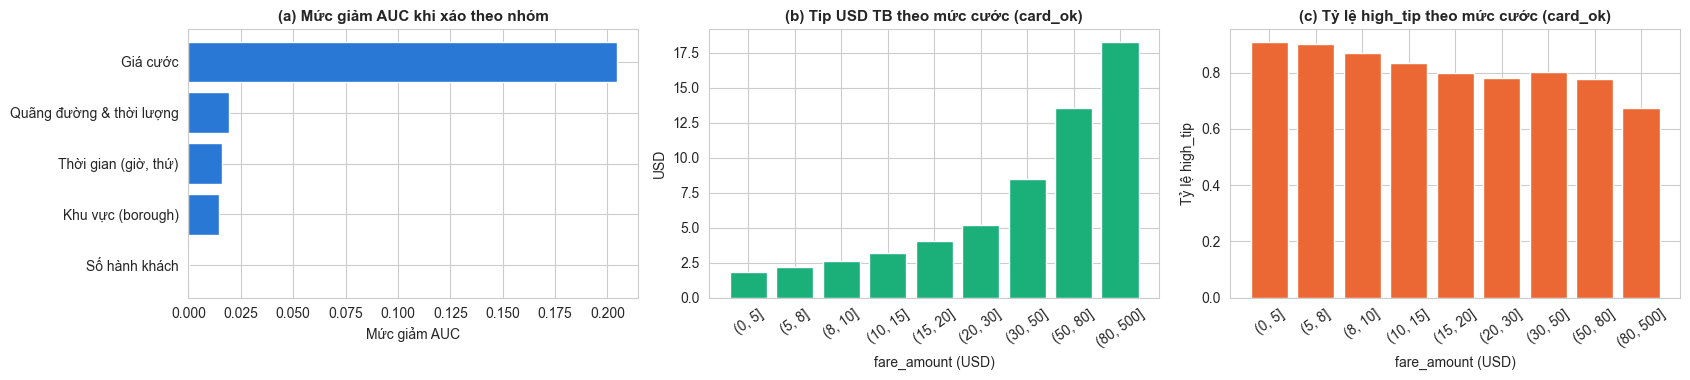

In [10]:
sample_idx = X1_test_enc.sample(60000, random_state=RANDOM_STATE).index
X_imp, y_imp = X1_test_enc.loc[sample_idx], y1_test.loc[sample_idx]
FEATURE_GROUPS = {
    "Giá cước": ["fare_amount", "fare_per_mile", "fare_per_min"],
    "Quãng đường & thời lượng": ["trip_distance", "trip_duration_min", "speed_mph"],
    "Thời gian (giờ, thứ)": ["pickup_hour", "hour_sin", "hour_cos", "time_of_day", "pickup_dayofweek", "is_weekend"],
    "Khu vực (borough)": ["pickup_borough", "dropoff_borough", "same_borough"],
    "Số hành khách": ["passenger_count"],
}
rng = np.random.default_rng(RANDOM_STATE)
base_auc = roc_auc_score(y_imp, hgb.predict_proba(X_imp)[:, 1])
imp_group = {}
for name, cols in FEATURE_GROUPS.items():
    drops = []
    for _ in range(5):
        X_perm = X_imp.copy()
        X_perm[cols] = X_imp[cols].values[rng.permutation(len(X_imp))]
        drops.append(base_auc - roc_auc_score(y_imp, hgb.predict_proba(X_perm)[:, 1]))
    imp_group[name] = np.mean(drops)
imp_group = pd.Series(imp_group).sort_values()
single = permutation_importance(hgb, X_imp, y_imp, n_repeats=5, random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=1)
imp_single = pd.Series(single.importances_mean, index=X_imp.columns).sort_values(ascending=False)
print("Grouped AUC drop:\n", imp_group.sort_values(ascending=False).round(4).to_string())
print("\nTop single features:\n", imp_single.head(6).round(4).to_string())

card_ok = trips[trips["card_ok"]]
FARE_BINS = [0, 5, 8, 10, 15, 20, 30, 50, 80, 500]
by_fare = card_ok.groupby(pd.cut(card_ok["fare_amount"], FARE_BINS), observed=True).agg(
    mean_tip_usd=("tip_amount", "mean"), high_tip_rate=("high_tip", "mean"), zero_tip_share=("zero_tip", "mean"))
print("\n", by_fare.round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 3.9))
axes[0].barh(imp_group.index, imp_group.values, color=C_BLUE)
axes[0].set_title("(a) Mức giảm AUC khi xáo theo nhóm")
axes[0].set_xlabel("Mức giảm AUC")
labels = [str(i) for i in by_fare.index]
axes[1].bar(labels, by_fare["mean_tip_usd"], color=C_AQUA)
axes[1].set_title("(b) Tip USD TB theo mức cước (card_ok)")
axes[1].set_ylabel("USD")
axes[2].bar(labels, by_fare["high_tip_rate"], color=C_ORANGE)
axes[2].set_title("(c) Tỷ lệ high_tip theo mức cước (card_ok)")
axes[2].set_ylabel("Tỷ lệ high_tip")
for ax in axes[1:]:
    ax.set_xlabel("fare_amount (USD)")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

**Insight:** "giá cước quyết định tip" là hiệu ứng của cách định nghĩa nhãn — chuyến đắt mang lại **nhiều tip USD hơn**, không ít hơn.

**[BẰNG CHỨNG TỪ DỮ LIỆU]**
- Giảm AUC theo nhóm: **Giá cước 0.2044** ≫ Quãng đường 0.0193 > Thời gian 0.0158 > Khu vực 0.0148 > Hành khách 0.0004.
- Tip USD tăng **1.86 → 8.51 → 18.25 USD** (cước ≤ 5 → 30–50 → > 80), tỷ lệ không tip phẳng **4.4–5.5%** (cước 5–80 USD); chỉ high_tip giảm **0.91 → 0.67** vì fare nằm ở mẫu số.

**Tác động:** không dùng `high_tip` làm KPI cho tài xế. **[GIẢ THUYẾT/SUY LUẬN]** nút tip tính % trên tổng tiền gồm phụ phí cố định → chuyến rẻ dễ vượt 15% fare (bằng chứng H7, 4.3).

#### 4.1.4. Artifact dữ liệu: chuyến thẻ `RatecodeID = 99`

                           RatecodeID khác 99  RatecodeID = 99
trips                          2,503,686.0000     140,071.0000
zero_tip_share                         0.0477           1.0000
vendor1_share                          0.1810           0.9998
mean_congestion_surcharge              2.3750           0.0005
pickup_manhattan_share                 0.9108           0.3058

Top pickup zones (RatecodeID=99): {'East New York': 3871, 'Central Harlem North': 3508, 'Crown Heights North': 3350, 'East Harlem South': 2669}



                 r99_share  high_tip_all_card  high_tip_card_ok
pickup_borough                                                
Manhattan          0.0184             0.8202            0.8356
Queens             0.0949             0.7181            0.7934
Brooklyn           0.8473             0.1196            0.7833
Bronx              0.9760             0.0160            0.6642



                       AUC  Recall low_tip @0.5  Lift low_tip decile 1
Toàn bộ test       0.7164               0.2471                 3.1427
Loại RatecodeID=99 0.6226               0.0065                 1.6448


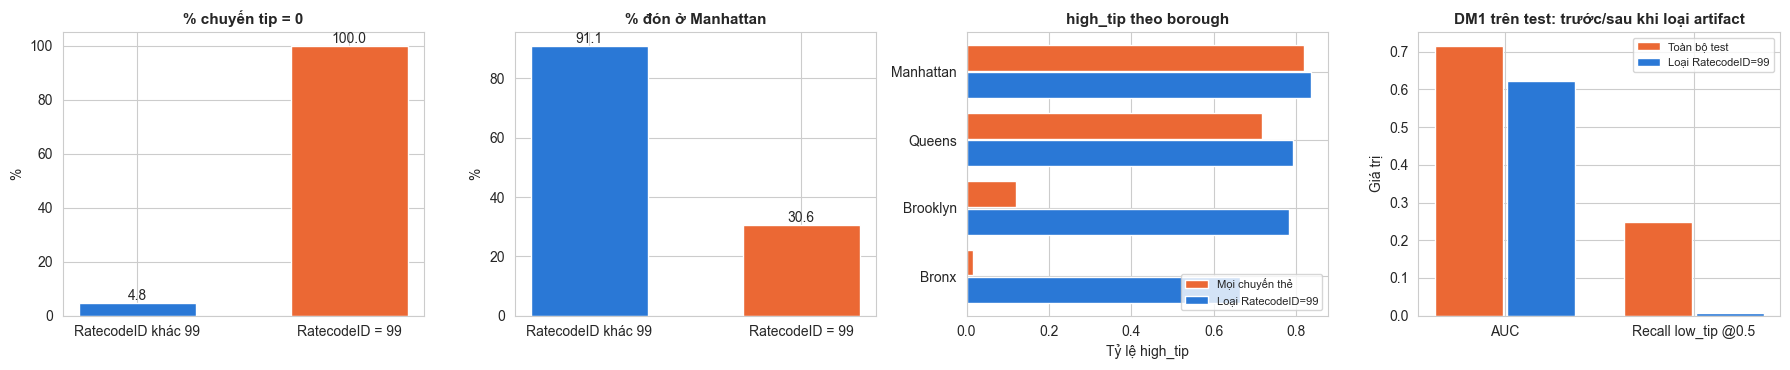

In [11]:
card = trips[trips["is_card"]]
r99_profile = card.groupby("is_r99").agg(
    trips=("high_tip", "size"), zero_tip_share=("zero_tip", "mean"),
    vendor1_share=("VendorID", lambda s: (s == 1).mean()),
    mean_congestion_surcharge=("congestion_surcharge", "mean"),
    pickup_manhattan_share=("pickup_borough", lambda s: (s == "Manhattan").mean()))
r99_profile.index = ["RatecodeID khác 99", "RatecodeID = 99"]
print(r99_profile.T.round(4).to_string())
print("\nTop pickup zones (RatecodeID=99):", card.loc[card["is_r99"], "pickup_zone"].value_counts().head(4).to_dict())

boro = pd.DataFrame({"r99_share": card.groupby("pickup_borough")["is_r99"].mean(),
                     "high_tip_all_card": card.groupby("pickup_borough")["high_tip"].mean(),
                     "high_tip_card_ok": card_ok.groupby("pickup_borough")["high_tip"].mean()})
boro = boro.loc[["Manhattan", "Queens", "Brooklyn", "Bronx"]]
print("\n", boro.round(4).to_string())


def subset_metrics(mask):
    y, p = y_test_arr[mask], p_hgb[mask]
    return {"AUC": roc_auc_score(y, p), "Recall low_tip @0.5": recall_score(y, (p >= 0.5).astype(int), pos_label=0),
            "Lift low_tip decile 1": decile_table(1 - y, 1 - p).loc[1, "lift"]}


model_quality = pd.DataFrame([subset_metrics(np.ones(len(y_test_arr), bool)), subset_metrics(~r99_flag)],
                             index=["Toàn bộ test", "Loại RatecodeID=99"])
print("\n", model_quality.round(4).to_string())

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, col, label in [(axes[0], "zero_tip_share", "% chuyến tip = 0"),
                       (axes[1], "pickup_manhattan_share", "% đón ở Manhattan")]:
    ax.bar(r99_profile.index, r99_profile[col] * 100, color=[C_BLUE, C_ORANGE], width=0.55)
    for i, v in enumerate(r99_profile[col] * 100):
        ax.text(i, v, f"{v:.1f}", ha="center", va="bottom")
    ax.set_title(label)
    ax.set_ylabel("%")
yy = np.arange(len(boro))
axes[2].barh(yy - 0.2, boro["high_tip_all_card"], height=0.38, color=C_ORANGE, label="Mọi chuyến thẻ")
axes[2].barh(yy + 0.2, boro["high_tip_card_ok"], height=0.38, color=C_BLUE, label="Loại RatecodeID=99")
axes[2].set_yticks(yy, boro.index)
axes[2].invert_yaxis()
axes[2].set_title("high_tip theo borough")
axes[2].set_xlabel("Tỷ lệ high_tip")
axes[2].legend(fontsize=8)
mq = model_quality[["AUC", "Recall low_tip @0.5"]]
xx = np.arange(len(mq.columns))
for i, (name, c) in enumerate(zip(mq.index, [C_ORANGE, C_BLUE])):
    axes[3].bar(xx + (i - 0.5) * 0.38, mq.loc[name], width=0.36, color=c, label=name)
axes[3].set_xticks(xx, mq.columns)
axes[3].set_title("DM1 trên test: trước/sau khi loại artifact")
axes[3].set_ylabel("Giá trị")
axes[3].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Insight:** 140,071 chuyến thẻ `RatecodeID = 99` (5.3% DM1) không phản ánh hành vi tip — đây là artifact và là nguồn chính của "năng lực" DM1.

**[BẰNG CHỨNG TỪ DỮ LIỆU]**
- Tip = 0 ở **100.0%** chuyến (còn lại 4.8%), VendorID 1 **99.98%**, congestion surcharge TB **0.0005** vs 2.38 USD, chỉ **30.6%** đón ở Manhattan (còn lại 91.1%); zone nhiều nhất: East New York, Central Harlem North, Crown Heights North.
- Loại nhóm 99: high_tip Bronx **0.016 → 0.664**, Brooklyn **0.120 → 0.783**.
- DM1 trên test đã loại: AUC **0.7164 → 0.6226**, recall low_tip **0.2471 → 0.0065**, lift decile 1 **3.14 → 1.64**.

**Tác động:** kết luận "Bronx/Brooklyn tip thấp" ở Modeling cũ là **sai**; DM1 hiện học lỗi dữ liệu. **[GIẢ THUYẾT/SUY LUẬN]** nhiều khả năng là chuyến hợp đồng/voucher ghi nhận là "thẻ".

#### 4.1.5. Tác động của DM1 lên tài xế và khách hàng

**Backtest:** điểm mỗi ô zone × khung giờ tính trên **train**, kết quả đo trên chuyến thật của **test** (`card_ok`); chọn top 20% ô. **Khách hàng:** giả lập tài xế né 20% ô có điểm DM1 thấp nhất. Giới hạn: train/test cùng tháng.

                               share_of_test_trips  rev_per_occ_hour  tip_usd_per_trip  high_tip_rate  airport_share  delta_usd_per_shift
strategy                                                                                                                                 
Hiện trạng (mọi ô)                          0.9892           82.8715            4.4691         0.8328         0.0966               0.0000
Kinh nghiệm: chỉ Manhattan                  0.9092           79.3750            3.8071         0.8361         0.0207             -16.7831
DM1: top 20% P(high_tip)                    0.3028           80.2074            3.9876         0.8557         0.0698             -12.7874
Lịch sử: top 20% tip USD                    0.1745           89.8679            8.0728         0.8178         0.4674              33.5829
Lịch sử: top 20% thu nhập/giờ               0.0874          107.4742            7.8654         0.8100         0.5139             118.0930
Spearman over 437 cells: DM1 score


                              trips_per_day  share_of_all_trips  share_outside_manhattan                                                                               top_zones (trips/day)
scenario                                                                                                                                                                                   
Điểm DM1 gồm RatecodeID=99      2,784.9355              0.0222                   0.7338  Central Harlem North 360, Crown Heights North 186, Washington Heights South 173, East New York 144
Điểm DM1 loại RatecodeID=99    17,922.8387              0.1431                   0.2795                 JFK Airport 4533, East Village 1089, West Village 782, Financial District North 728


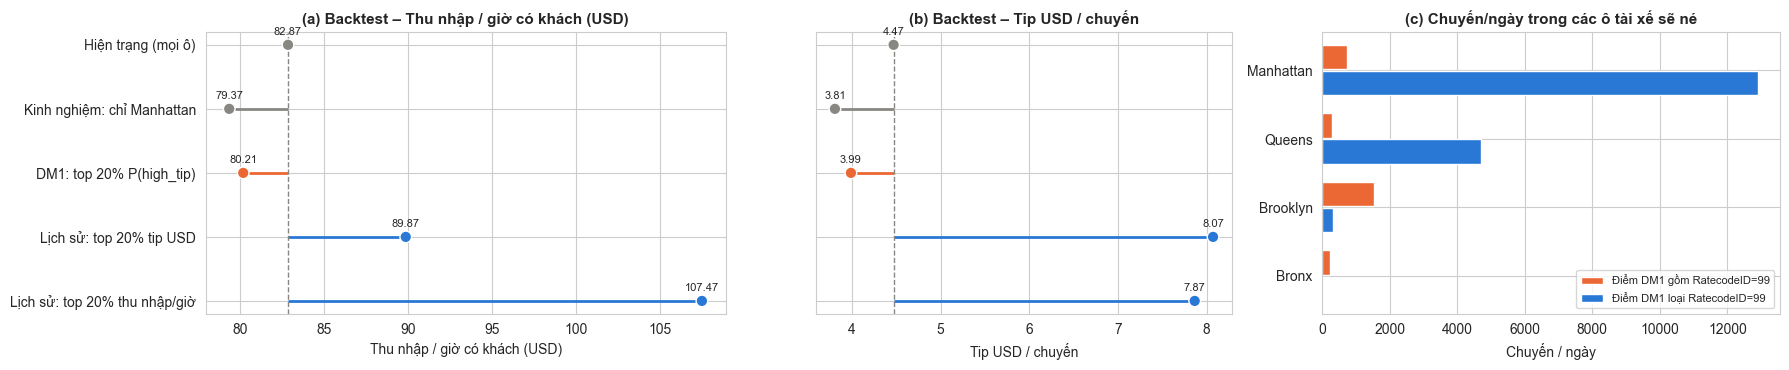

In [12]:
TOP_SHARE, MIN_TRAIN_CELL = 0.20, 200
CELL = ["PULocationID", "slot"]
train_meta = dm1.loc[idx_train].copy()
train_meta["p_hgb"] = hgb.predict_proba(X1_train_enc)[:, 1]


def in_scope(df):
    return df[df["pu_in_month"] & ~df["PULocationID"].isin(UNKNOWN_ZONE_IDS)]


def cell_table(df):
    g = df.groupby(CELL)
    return pd.DataFrame({"n": g.size(), "borough": g["pickup_borough"].first(), "dm1_score": g["p_hgb"].mean(),
                         "tip_usd": g["tip_amount"].mean(),
                         "rev_per_occ_hour": g["revenue"].sum() / g["trip_duration_min"].sum() * 60})


tr_ok = cell_table(in_scope(train_meta[train_meta["card_ok"]]))
tr_ok = tr_ok[tr_ok["n"] >= MIN_TRAIN_CELL]
top = lambda s: set(s[s >= s.quantile(1 - TOP_SHARE)].index)
STRATEGIES = {"Hiện trạng (mọi ô)": set(tr_ok.index),
              "Kinh nghiệm: chỉ Manhattan": set(tr_ok.index[tr_ok["borough"] == "Manhattan"]),
              "DM1: top 20% P(high_tip)": top(tr_ok["dm1_score"]),
              "Lịch sử: top 20% tip USD": top(tr_ok["tip_usd"]),
              "Lịch sử: top 20% thu nhập/giờ": top(tr_ok["rev_per_occ_hour"])}
te_ok = in_scope(test_meta[test_meta["card_ok"]])
te_key = pd.MultiIndex.from_frame(te_ok[CELL])
rows = []
for name, cells_ in STRATEGIES.items():
    m = te_key.isin(list(cells_))
    s = te_ok[m]
    rows.append({"strategy": name, "share_of_test_trips": m.mean(),
                 "rev_per_occ_hour": s["revenue"].sum() / s["trip_duration_min"].sum() * 60,
                 "tip_usd_per_trip": s["tip_amount"].mean(), "high_tip_rate": s["high_tip"].mean(),
                 "airport_share": s["is_airport"].mean()})
backtest = pd.DataFrame(rows).set_index("strategy")
sq = backtest.iloc[0]
backtest["delta_usd_per_shift"] = (backtest["rev_per_occ_hour"] - sq["rev_per_occ_hour"]) * SHIFT_H * UTIL
print(backtest.round(4).to_string())
print(f"Spearman over {len(tr_ok)} cells: DM1 score vs tip USD = {spearmanr(tr_ok['dm1_score'], tr_ok['tip_usd'])[0]:.4f}"
      f" | vs revenue/occupied hour = {spearmanr(tr_ok['dm1_score'], tr_ok['rev_per_occ_hour'])[0]:.4f}")

# Customers: trips/day inside the cells drivers would avoid
tr_card = cell_table(in_scope(train_meta))
tr_card = tr_card[tr_card["n"] >= MIN_TRAIN_CELL]
bottom = lambda s: set(s[s <= s.quantile(TOP_SHARE)].index)
zs_key = pd.MultiIndex.from_frame(zone_src[CELL])
rows, by_boro = [], {}
for name, cells_ in {"Điểm DM1 gồm RatecodeID=99": bottom(tr_card["dm1_score"]),
                     "Điểm DM1 loại RatecodeID=99": bottom(tr_ok["dm1_score"])}.items():
    m = zs_key.isin(list(cells_))
    s = zone_src[m]
    rows.append({"scenario": name, "trips_per_day": m.sum() / N_DAYS, "share_of_all_trips": m.mean(),
                 "share_outside_manhattan": (s["pickup_borough"] != "Manhattan").mean(),
                 "top_zones (trips/day)": ", ".join(f"{z} {v:.0f}" for z, v in
                                                    (s["pickup_zone"].value_counts() / N_DAYS).head(4).items())})
    by_boro[name] = s.groupby("pickup_borough").size() / N_DAYS
avoid_tbl = pd.DataFrame(rows).set_index("scenario")
print("\n", avoid_tbl.to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 3.8), gridspec_kw={"width_ratios": [1.25, 1, 1.1]})
colors = [C_GREY, C_GREY, C_ORANGE, C_BLUE, C_BLUE]
y = np.arange(len(backtest))
for k, (ax, col, label) in enumerate([(axes[0], "rev_per_occ_hour", "Thu nhập / giờ có khách (USD)"),
                                      (axes[1], "tip_usd_per_trip", "Tip USD / chuyến")]):
    ax.hlines(y, sq[col], backtest[col], color=colors, lw=2)
    ax.scatter(backtest[col], y, color=colors, s=70, zorder=3, edgecolor="white")
    ax.axvline(sq[col], ls="--", lw=1, color=C_GREY)
    for yi, v in zip(y, backtest[col]):
        ax.annotate(f"{v:.2f}", (v, yi), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
    ax.set_yticks(y, backtest.index if k == 0 else [""] * len(y))
    ax.invert_yaxis()
    ax.set_title(f"({'ab'[k]}) Backtest – {label}")
    ax.set_xlabel(label)
bb = pd.DataFrame(by_boro).fillna(0).reindex(["Manhattan", "Queens", "Brooklyn", "Bronx"]).fillna(0)
yy = np.arange(len(bb))
for i, (name, c) in enumerate(zip(bb.columns, [C_ORANGE, C_BLUE])):
    axes[2].barh(yy + (i - 0.5) * 0.38, bb[name], height=0.36, color=c, label=name)
axes[2].set_yticks(yy, bb.index)
axes[2].invert_yaxis()
axes[2].set_title("(c) Chuyến/ngày trong các ô tài xế sẽ né")
axes[2].set_xlabel("Chuyến / ngày")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Insight:** DM1 đúng mục tiêu của nó (high_tip cao nhất 0.856) nhưng **ngược KPI tài xế**, và nếu dùng để né khu vực sẽ hại khách.

**[BẰNG CHỨNG TỪ DỮ LIỆU]**

| Chiến lược | USD/giờ có khách | Δ USD/ca | Tip USD/chuyến | % chuyến test khả dụng |
|---|---|---|---|---|
| Hiện trạng | 82.87 | – | 4.47 | 98.9% |
| Kinh nghiệm: chỉ Manhattan | 79.37 | −16.78 | 3.81 | 90.9% |
| **DM1 top 20%** | **80.21** | **−12.79** | **3.99** | 30.3% |
| Lịch sử top 20% tip USD | 89.87 | +33.58 | 8.07 | 17.5% |
| Lịch sử top 20% thu nhập/giờ | 107.47 | +118.09 | 7.87 | 8.7% |

- Điểm DM1 vs tip USD: ρ = **−0.41**; vs thu nhập/giờ: ρ = −0.21.
- Né 20% ô điểm DM1 thấp nhất: điểm **gồm** artifact → **2,785** chuyến/ngày, **73.4%** ngoài Manhattan (Central Harlem North 360/ngày, Crown Heights North 186); điểm **đã loại** → **17,923** chuyến/ngày (14.3%), gồm JFK 4,533/ngày — nơi tip USD cao nhất.

**[GIẢ THUYẾT/SUY LUẬN]** hai chiến lược lịch sử thắng nhờ sân bay (47–51% chuyến) nhưng chưa trừ thời gian xếp hàng → lợi ích bị phóng đại; DM1 thua ngay cả khi chưa tính thời gian chờ.

**Tác động:** tài xế — làm theo DM1 mất ~12.8 USD/ca · khách — khu dân cư Harlem/Brooklyn có thể bị rút xe vì lỗi dữ liệu · nền tảng — chỉ dùng model để **bổ sung** xe, không rút xe (quy định TLC cấm từ chối chở khách theo điểm đến).

#### 4.1.6. DM2: các cụm có giá trị cho điều phối không?

Đo các chỉ số **mô hình không thấy khi phân cụm** (doanh thu, tip, sân bay); k=6 để so sánh.

k=5:
             share_trips  share_revenue  revenue_per_trip  avg_duration  revenue_per_occ_hour  airport_share  high_tip_card_ok  tip_usd_card_ok
cluster_k5                                                                                                                                    
0                0.2034         0.1650           19.8075       14.1986               83.7018         0.0334            0.8508           3.7942
1                0.1369         0.1179           21.0371       15.6571               80.6170         0.0574            0.8391           3.8698
2                0.1783         0.1811           24.8175       17.9910               82.7663         0.0843            0.8016           4.5231
3                0.1947         0.2832           35.5352       30.1218               70.7830         0.1923            0.8225           6.5964
4                0.2867         0.2527           21.5273       16.5965               77.8257         0.0442            0.8363           

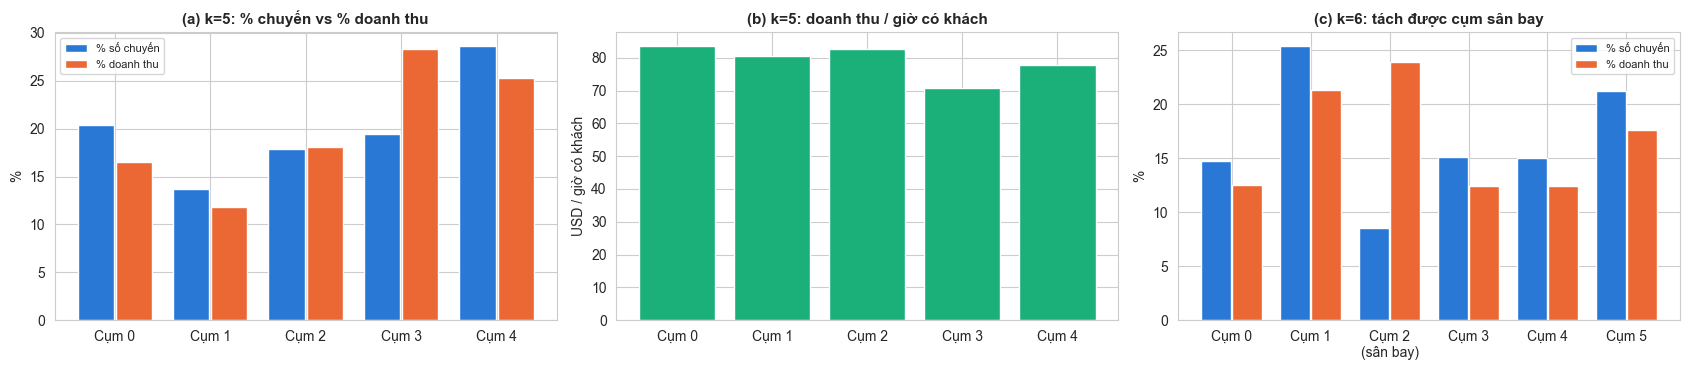

In [13]:
def cluster_business_profile(df, col):
    g, ok = df.groupby(col), df[df["card_ok"]].groupby(col)
    return pd.DataFrame({"share_trips": g.size() / len(df), "share_revenue": g["revenue"].sum() / df["revenue"].sum(),
                         "revenue_per_trip": g["revenue"].mean(), "avg_duration": g["trip_duration_min"].mean(),
                         "revenue_per_occ_hour": g["revenue"].sum() / g["trip_duration_min"].sum() * 60,
                         "airport_share": g["is_airport"].mean(), "high_tip_card_ok": ok["high_tip"].mean(),
                         "tip_usd_card_ok": ok["tip_amount"].mean()})


prof_k5, prof_k6 = cluster_business_profile(trips, "cluster_k5"), cluster_business_profile(trips, "cluster_k6")
ap = prof_k6["airport_share"].idxmax()
rest = trips[trips["cluster_k6"] != ap]
ref_rate = rest["revenue"].sum() / rest["trip_duration_min"].sum() * 60
opp_cost = (ref_rate - prof_k6.loc[ap, "revenue_per_occ_hour"]) * prof_k6.loc[ap, "avg_duration"] / 60
print("k=5:\n", prof_k5.round(4).to_string())
print("\nk=6:\n", prof_k6.round(4).to_string())
print(f"\nAirport cluster k=6 = {ap} | other clusters {ref_rate:.2f} USD/occupied hour | "
      f"[assumption] opportunity cost {opp_cost:.2f} USD/trip, "
      f"{opp_cost * (trips['cluster_k6'] == ap).sum():,.0f} USD/month")

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
x5 = np.arange(len(prof_k5))
axes[0].bar(x5 - 0.2, prof_k5["share_trips"] * 100, width=0.38, color=C_BLUE, label="% số chuyến")
axes[0].bar(x5 + 0.2, prof_k5["share_revenue"] * 100, width=0.38, color=C_ORANGE, label="% doanh thu")
axes[0].set_xticks(x5, [f"Cụm {i}" for i in prof_k5.index])
axes[0].set_title("(a) k=5: % chuyến vs % doanh thu")
axes[0].set_ylabel("%")
axes[0].legend(fontsize=8)
axes[1].bar(x5, prof_k5["revenue_per_occ_hour"], color=C_AQUA)
axes[1].set_xticks(x5, [f"Cụm {i}" for i in prof_k5.index])
axes[1].set_title("(b) k=5: doanh thu / giờ có khách")
axes[1].set_ylabel("USD / giờ có khách")
x6 = np.arange(len(prof_k6))
axes[2].bar(x6 - 0.2, prof_k6["share_trips"] * 100, width=0.38, color=C_BLUE, label="% số chuyến")
axes[2].bar(x6 + 0.2, prof_k6["share_revenue"] * 100, width=0.38, color=C_ORANGE, label="% doanh thu")
axes[2].set_xticks(x6, [f"Cụm {i}\n(sân bay)" if i == ap else f"Cụm {i}" for i in prof_k6.index])
axes[2].set_title("(c) k=6: tách được cụm sân bay")
axes[2].set_ylabel("%")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Insight:** cụm DM2 khác rõ về **giá trị kinh tế** (dù model không thấy biến giá) nhưng **không** khác về tip → DM2 phục vụ điều phối, không dự đoán tip.

**[BẰNG CHỨNG TỪ DỮ LIỆU]**
- k=5: cụm 3 (dài/liên borough) = **19.5%** chuyến – **28.3%** doanh thu, năng suất thấp nhất **70.78 USD/giờ có khách** (cụm 0 tan tầm: 83.70). high_tip giữa các cụm chỉ 0.80–0.85.
- k=6 tách cụm sân bay: **8.5%** chuyến – **23.9%** doanh thu, 68.44 USD/chuyến, xe bận **55.5 phút**, 74.06 vs 78.91 USD/giờ của các cụm khác.
- **[GIẢ ĐỊNH]** chi phí cơ hội thời gian có khách: 4.48 USD/chuyến sân bay ≈ 1.48 triệu USD/tháng (chưa tính hàng chờ sân bay và thời gian chờ giữa các chuyến nội đô).

**Tác động:** nền tảng — lịch điều phối riêng cho cụm dài/sân bay; tài xế — chuyến ngắn giờ tan tầm có năng suất giờ cao nhất.

### 4.2. Phân tích theo khu vực và khung giờ

Theo **zone đón**, giờ đón trong 05/2026. Khung giờ = `time_of_day` × ngày thường/cuối tuần. `revenue_per_trip` = fare + tip (mọi thanh toán); `high_tip_rate`, `avg_tip_usd`, `tip_pct_of_fare` (Σtip ÷ Σfare) trên `card_ok`. Ngưỡng ổn định: zone ≥ 500, ô zone × khung giờ ≥ 100 chuyến `card_ok`.

Zones eligible: 75/257 (94.85% of trips) | zone x slot cells eligible: 530/1991

By slot:
                         trips  revenue_per_trip  high_tip_rate  avg_tip_usd  tip_pct_of_fare
slot                                                                                        
weekday|early_morning  410629           24.5529         0.8259       4.1476           0.2290
weekday|midday         838997           25.7431         0.8429       4.7531           0.2291
weekday|peak_hour      647087           23.9350         0.8437       4.6656           0.2473
weekday|late_night     754006           24.6751         0.8305       4.4966           0.2317
weekend|early_morning   95247           23.4640         0.8369       4.3185           0.2281
weekend|midday         388557           23.8340         0.8360       4.3775           0.2271
weekend|peak_hour      296181           23.9110         0.8257       4.3855           0.2227
weekend|late_night     451024           23.0429         0.7906       4.1

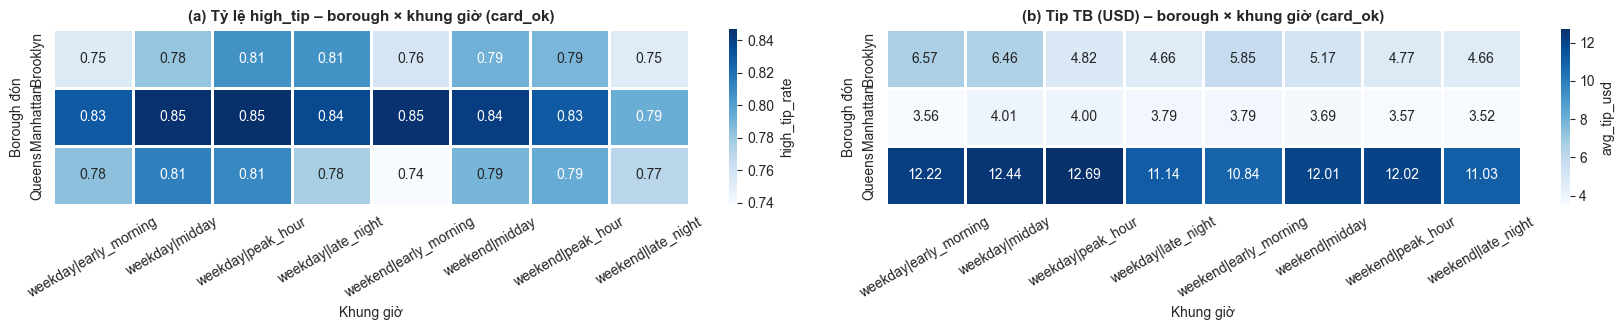

In [14]:
MIN_CARD_ZONE, MIN_CARD_CELL = 500, 100
ZONE_KEYS = ["PULocationID", "pickup_borough", "pickup_zone"]


def zone_metrics(df, keys):
    g, ok = df.groupby(keys, observed=True), df[df["card_ok"]].groupby(keys, observed=True)
    out = pd.DataFrame({
        "trips": g.size(), "revenue_per_trip": g["revenue"].mean(), "fare_per_trip": g["fare_amount"].mean(),
        "avg_distance": g["trip_distance"].mean(), "avg_duration": g["trip_duration_min"].mean(),
        "revenue_per_occ_hour": g["revenue"].sum() / g["trip_duration_min"].sum() * 60,
        "cash_share": g["is_cash"].mean(), "airport_share": g["is_airport"].mean(),
        "airport_fee_share": g["has_airport_fee"].mean(), "card_ok_trips": ok.size(),
        "high_tip_rate": ok["high_tip"].mean(), "avg_tip_usd": ok["tip_amount"].mean(),
        "tip_pct_of_fare": ok["tip_amount"].sum() / ok["fare_amount"].sum(), "zero_tip_share": ok["zero_tip"].mean()})
    out["card_ok_trips"] = out["card_ok_trips"].fillna(0).astype(int)
    return out


slot_tbl = zone_metrics(zone_src, ["slot"]).reindex(SLOT_ORDER)
zone_tbl = zone_metrics(zone_src, ZONE_KEYS).reset_index()
zone_tbl["trips_per_day"] = zone_tbl["trips"] / N_DAYS
zone_elig = zone_tbl[zone_tbl["card_ok_trips"] >= MIN_CARD_ZONE].copy()
cell_tbl = zone_metrics(zone_src, ZONE_KEYS + ["slot"]).reset_index()
cell_elig = cell_tbl[cell_tbl["card_ok_trips"] >= MIN_CARD_CELL].copy()
print(f"Zones eligible: {len(zone_elig)}/{len(zone_tbl)} ({zone_elig['trips'].sum() / zone_tbl['trips'].sum():.2%} of trips)"
      f" | zone x slot cells eligible: {len(cell_elig)}/{len(cell_tbl)}")
cols = ["trips", "revenue_per_trip", "high_tip_rate", "avg_tip_usd", "tip_pct_of_fare"]
print("\nBy slot:\n", slot_tbl[cols].round(4).to_string())
show = ["pickup_borough", "pickup_zone", "trips_per_day", "revenue_per_trip", "high_tip_rate", "avg_tip_usd",
        "tip_pct_of_fare"]
print("\nTop 5 zones by volume:\n", zone_elig.nlargest(5, "trips")[show].round(4).to_string(index=False))
print("\nBottom 5 zones by high_tip:\n", zone_elig.nsmallest(5, "high_tip_rate")[show].round(4).to_string(index=False))

boro_slot = zone_metrics(zone_src[zone_src["pickup_borough"].isin(["Manhattan", "Queens", "Brooklyn"])],
                         ["pickup_borough", "slot"]).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(17, 3.4))
for ax, metric, title in [(axes[0], "high_tip_rate", "(a) Tỷ lệ high_tip"), (axes[1], "avg_tip_usd", "(b) Tip TB (USD)")]:
    pv = boro_slot.pivot(index="pickup_borough", columns="slot", values=metric)[SLOT_ORDER]
    sns.heatmap(pv, annot=True, fmt=".2f", cmap="Blues", cbar_kws={"label": metric}, ax=ax, linewidths=2, linecolor="white")
    ax.set_title(title + " – borough × khung giờ (card_ok)")
    ax.set_xlabel("Khung giờ")
    ax.set_ylabel("Borough đón")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Insight:** khung giờ tạo khác biệt nhỏ; khu vực tạo khác biệt lớn — và "tip % thấp" thường đi kèm "tip USD cao".

**[BẰNG CHỨNG TỪ DỮ LIỆU]**
- Khung giờ: high_tip **0.7906** (đêm cuối tuần) → **0.8437** (cao điểm ngày thường); giữa trưa ngày thường nhiều chuyến nhất (838,997) và doanh thu/chuyến cao nhất (25.74 USD).
- Borough: Manhattan high_tip 0.79–0.85, tip 3.52–4.01 USD; Queens high_tip 0.74–0.81 nhưng tip **10.84–12.69 USD** (sân bay).
- JFK: 4,533 chuyến/ngày, **71.34 USD/chuyến**, tip **12.88 USD**, high_tip chỉ 0.7394. Thấp nhất: Central Harlem North (0.6610), Astoria (0.6948), Manhattanville (0.6975).

Cut-offs: high_tip median = 0.8127 | trips/day median = 1282.6
                         zones  high_tip  tip_usd  revenue_per_trip  share_of_trips                                                      examples
quadrant                                                                                                                                         
A. Lõi sinh lời             31    0.8395   3.7425           19.9974          0.6976  Upper East Side South, Upper East Side North, Midtown Center
B. Ngách tip cao             7    0.8391   4.0282           23.6613          0.0285              Manhattan Valley, Morningside Heights, Hudson Sq
C. Đông khách, tip thấp      7    0.7994   3.7578           21.7653          0.1275            JFK Airport, East Village, Greenwich Village South
D. Vùng biên                30    0.7745   4.7929           28.4489          0.0949             East Harlem South, SoHo, Financial District North


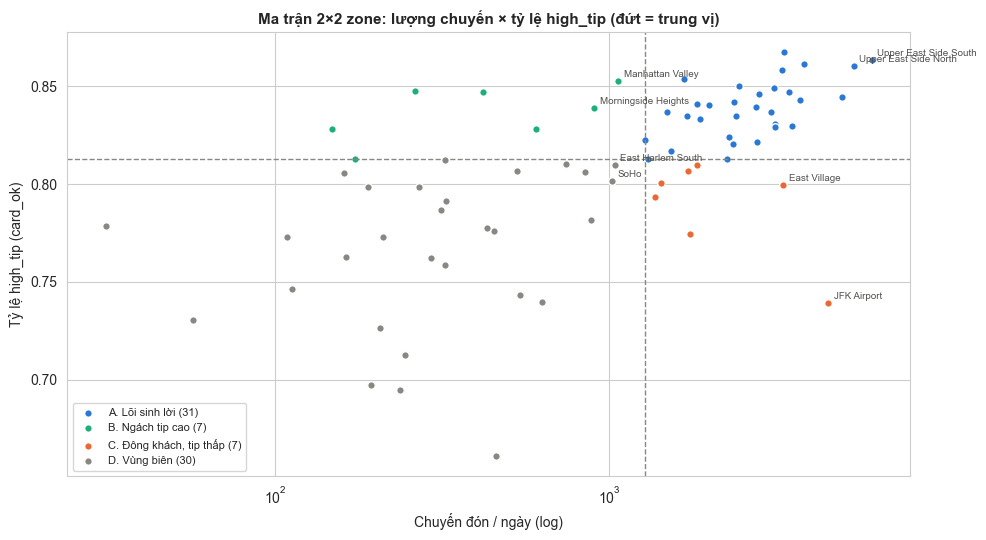

In [15]:
TIP_CUT, VOL_CUT = zone_elig["high_tip_rate"].median(), zone_elig["trips_per_day"].median()
QUAD = {(True, True): "A. Lõi sinh lời", (True, False): "B. Ngách tip cao",
        (False, True): "C. Đông khách, tip thấp", (False, False): "D. Vùng biên"}
zone_elig["quadrant"] = [QUAD[(t >= TIP_CUT, v >= VOL_CUT)] for t, v in zip(zone_elig["high_tip_rate"], zone_elig["trips_per_day"])]
quad = zone_elig.groupby("quadrant").agg(
    zones=("pickup_zone", "size"), trips=("trips", "sum"), high_tip=("high_tip_rate", "median"),
    tip_usd=("avg_tip_usd", "median"), revenue_per_trip=("revenue_per_trip", "median"))
quad["share_of_trips"] = quad.pop("trips") / zone_tbl["trips"].sum()
quad["examples"] = zone_elig.sort_values("trips", ascending=False).groupby("quadrant")["pickup_zone"].agg(
    lambda s: ", ".join(s.head(3)))
print(f"Cut-offs: high_tip median = {TIP_CUT:.4f} | trips/day median = {VOL_CUT:.1f}")
print(quad.round(4).to_string())

fig, ax = plt.subplots(figsize=(10, 5.5))
for (name, sub), c in zip(zone_elig.groupby("quadrant"), [C_BLUE, C_AQUA, C_ORANGE, C_GREY]):
    ax.scatter(sub["trips_per_day"], sub["high_tip_rate"], s=30, color=c, edgecolor="white", label=f"{name} ({len(sub)})")
    for _, r in sub.nlargest(2, "trips").iterrows():
        ax.annotate(r["pickup_zone"], (r["trips_per_day"], r["high_tip_rate"]), fontsize=7, xytext=(4, 3),
                    textcoords="offset points", color="#52514e")
ax.axvline(VOL_CUT, ls="--", lw=1, color=C_GREY)
ax.axhline(TIP_CUT, ls="--", lw=1, color=C_GREY)
ax.set_xscale("log")
ax.set_title("Ma trận 2×2 zone: lượng chuyến × tỷ lệ high_tip (đứt = trung vị)")
ax.set_xlabel("Chuyến đón / ngày (log)")
ax.set_ylabel("Tỷ lệ high_tip (card_ok)")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

**[BẰNG CHỨNG TỪ DỮ LIỆU]** (ngưỡng: high_tip 0.8127, 1,282.6 chuyến/ngày)

| Nhóm | Zone | % chuyến | high_tip | Tip USD | USD/chuyến | Ví dụ | Hàm ý |
|---|---|---|---|---|---|---|---|
| **A. Lõi sinh lời** | 31 | **69.8%** | 0.840 | 3.74 | 20.00 | Upper East Side South/North, Midtown Center | Thu nhập nền ổn định, duy trì phủ xe |
| **B. Ngách tip cao** | 7 | 2.9% | 0.839 | 4.03 | 23.66 | Manhattan Valley, Morningside Heights, Hudson Sq | Ứng viên "tip cao – ít xe" |
| **C. Đông khách, tip thấp** | 7 | 12.8% | 0.799 | 3.76 | 21.77 | JFK, East Village, Greenwich Village South | Sân bay: tip USD cao; khu ăn chơi: hay không tip |
| **D. Vùng biên** | 30 | 9.5% | 0.775 | **4.79** | **28.45** | East Harlem South, SoHo, Financial District North | Tip USD & doanh thu/chuyến cao nhất → không né |

### 4.3. Kịch bản "tip thấp" — góc nhìn khách hàng

Ô "tip thấp" = ô zone × khung giờ có high_tip thuộc **20% thấp nhất**; so với các ô còn lại.

Low-tip cut-off = 0.7771 | low cells = 106/530 | by slot: {'weekend|late_night': 31, 'weekday|early_morning': 14, 'weekday|midday': 13}
cell_group              Ô tip thấp  Ô còn lại
Quãng đường TB (dặm)        7.6702     2.7798
Fare TB (USD)              35.8568    18.8692
% chạm sân bay             35.6004     4.9817
% cuối tuần                58.3479    28.0592
% khác borough             38.3312    10.0861
% không báo thanh toán     32.1197    19.3417
high_tip (card_ok)          0.7451     0.8403
% không tip (card_ok)       8.6093     4.3769
Tip TB USD (card_ok)        8.1944     4.1383

Largest low-tip cells:
             pickup_zone               slot  trips  high_tip_rate  zero_tip_share  avg_tip_usd  avg_distance
            JFK Airport weekday|late_night  34419         0.7227          0.0745      12.1554       14.3480
           East Village weekend|late_night  33770         0.7567          0.1103       3.3418        2.6975
            JFK Airport     weekday|midday  26181      

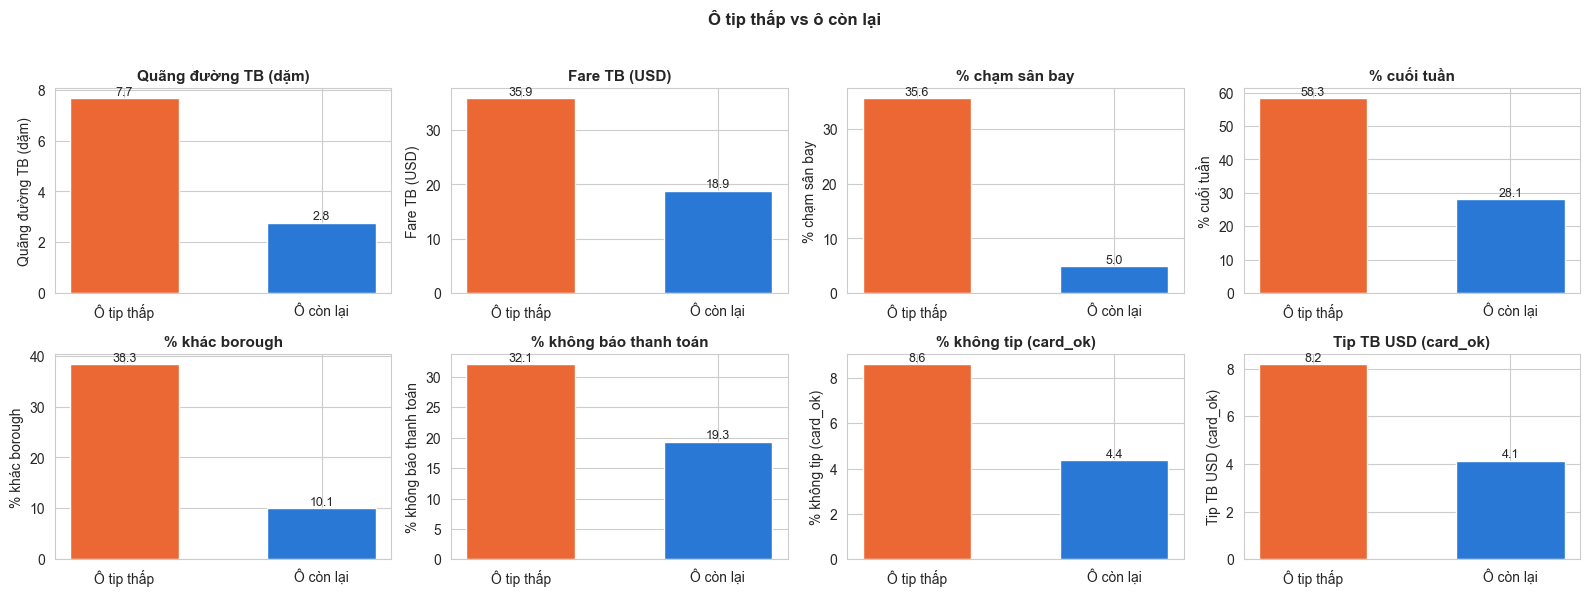

In [16]:
LOW_CUT = cell_elig["high_tip_rate"].quantile(0.20)
cell_elig["is_low"] = cell_elig["high_tip_rate"] <= LOW_CUT
key = zone_src["PULocationID"].astype(str) + "|" + zone_src["slot"]
ckey = cell_elig["PULocationID"].astype(str) + "|" + cell_elig["slot"]
grp = np.where(key.isin(set(ckey[cell_elig["is_low"]])), "Ô tip thấp", np.where(key.isin(set(ckey)), "Ô còn lại", None))
cmp_src = zone_src.assign(cell_group=grp).dropna(subset=["cell_group"])
cmp_src = cmp_src.assign(cross_borough=cmp_src["pickup_borough"] != cmp_src["dropoff_borough"],
                         unreported=cmp_src["payment_type"] == 0)
g, gok = cmp_src.groupby("cell_group"), cmp_src[cmp_src["card_ok"]].groupby("cell_group")
comparison = pd.DataFrame({
    "Quãng đường TB (dặm)": g["trip_distance"].mean(), "Fare TB (USD)": g["fare_amount"].mean(),
    "% chạm sân bay": g["is_airport"].mean() * 100, "% cuối tuần": g["is_weekend"].mean() * 100,
    "% khác borough": g["cross_borough"].mean() * 100, "% không báo thanh toán": g["unreported"].mean() * 100,
    "high_tip (card_ok)": gok["high_tip"].mean(), "% không tip (card_ok)": gok["zero_tip"].mean() * 100,
    "Tip TB USD (card_ok)": gok["tip_amount"].mean()}).T[["Ô tip thấp", "Ô còn lại"]]
low = cell_elig[cell_elig["is_low"]]
print(f"Low-tip cut-off = {LOW_CUT:.4f} | low cells = {len(low)}/{len(cell_elig)} | "
      f"by slot: {low['slot'].value_counts().head(3).to_dict()}")
print(comparison.round(4).to_string())
print("\nLargest low-tip cells:\n", low.nlargest(6, "trips")[["pickup_zone", "slot", "trips", "high_tip_rate",
                                                            "zero_tip_share", "avg_tip_usd", "avg_distance"]].round(4).to_string(index=False))

panels = ["Quãng đường TB (dặm)", "Fare TB (USD)", "% chạm sân bay", "% cuối tuần",
          "% khác borough", "% không báo thanh toán", "% không tip (card_ok)", "Tip TB USD (card_ok)"]
fig, axes = plt.subplots(2, 4, figsize=(16, 5.8))
for ax, label in zip(axes.flat, panels):
    vals = comparison.loc[label].astype(float)
    ax.bar(vals.index, vals.values, color=[C_ORANGE, C_BLUE], width=0.55)
    for i, v in enumerate(vals.values):
        ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(label)
    ax.set_ylabel(label)
fig.suptitle("Ô tip thấp vs ô còn lại", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Insight:** "tip thấp" gồm 2 kiểu khác nhau: **sân bay** (tip % thấp, tip USD cao) và **khu ăn chơi đêm cuối tuần** (tỷ lệ không tip gấp đôi).

**[BẰNG CHỨNG TỪ DỮ LIỆU]** 106/530 ô (high_tip ≤ 0.7771), **31 ô là đêm cuối tuần**. So với ô còn lại: quãng đường **7.67** vs 2.78 dặm, chạm sân bay **35.6%** vs 5.0%, cuối tuần 58.3% vs 28.1%, không tip **8.6%** vs 4.4%, nhưng tip TB **8.19** vs 4.14 USD; **32.1%** chuyến không báo thanh toán → phần lớn tip thật không quan sát được. Ô lớn nhất: JFK (tip 12–14 USD) và East Village / Lower East Side / Greenwich Village South đêm cuối tuần (không tip **9.8–12.1%**).

**Giả thuyết hành vi khách hàng [GIẢ THUYẾT/SUY LUẬN] và cách kiểm chứng:** H1 chuyến ngắn → tip thấp · H2 giá đã cao → tip % thấp (so trong cùng mức cước) · H3 kẹt xe → tip thấp (tốc độ là proxy) · H4 khách đi làm tip ít (sáng ngày thường vs sáng cuối tuần, cùng zone) · H5 cước cố định/thoả thuận → tip % thấp · H6 khu nhiều tiền mặt → khách thẻ tip ít · H7 nút gợi ý tip quyết định mức tip · H8 thu nhập dân cư (**không kiểm chứng được** – không có dữ liệu).

     Giả thuyết                                                                                        Bằng chứng
 H1 chuyến ngắn                                       ≤1 dặm: 0.890 (cao nhất); gap trong mọi khoảng: 0.063–0.107
  H2 giá đã cao                                                              gap trong cùng mức cước: 0.047–0.118
      H3 kẹt xe                                                                   0–5 mph 0.829 vs 8–12 mph 0.849
H4 khách đi làm                                                       53 zone: TB -1.21 điểm %, 62% zone thấp hơn
H5 cước cố định            Standard 0.836 vs JFK flat 0.764 vs Negotiated 0.671; % cước 2–5: ô thấp 32.7% vs 1.5%
    H6 tiền mặt                                                      Spearman = +0.483 (p = 1.1e-05) trên 75 zone
   H7 nút gợi ý 56.4% tip đúng 20% tổng trước tip; 68.5% đúng 20/25/30%; Manhattan Vendor1 0.864 vs Vendor2 0.829


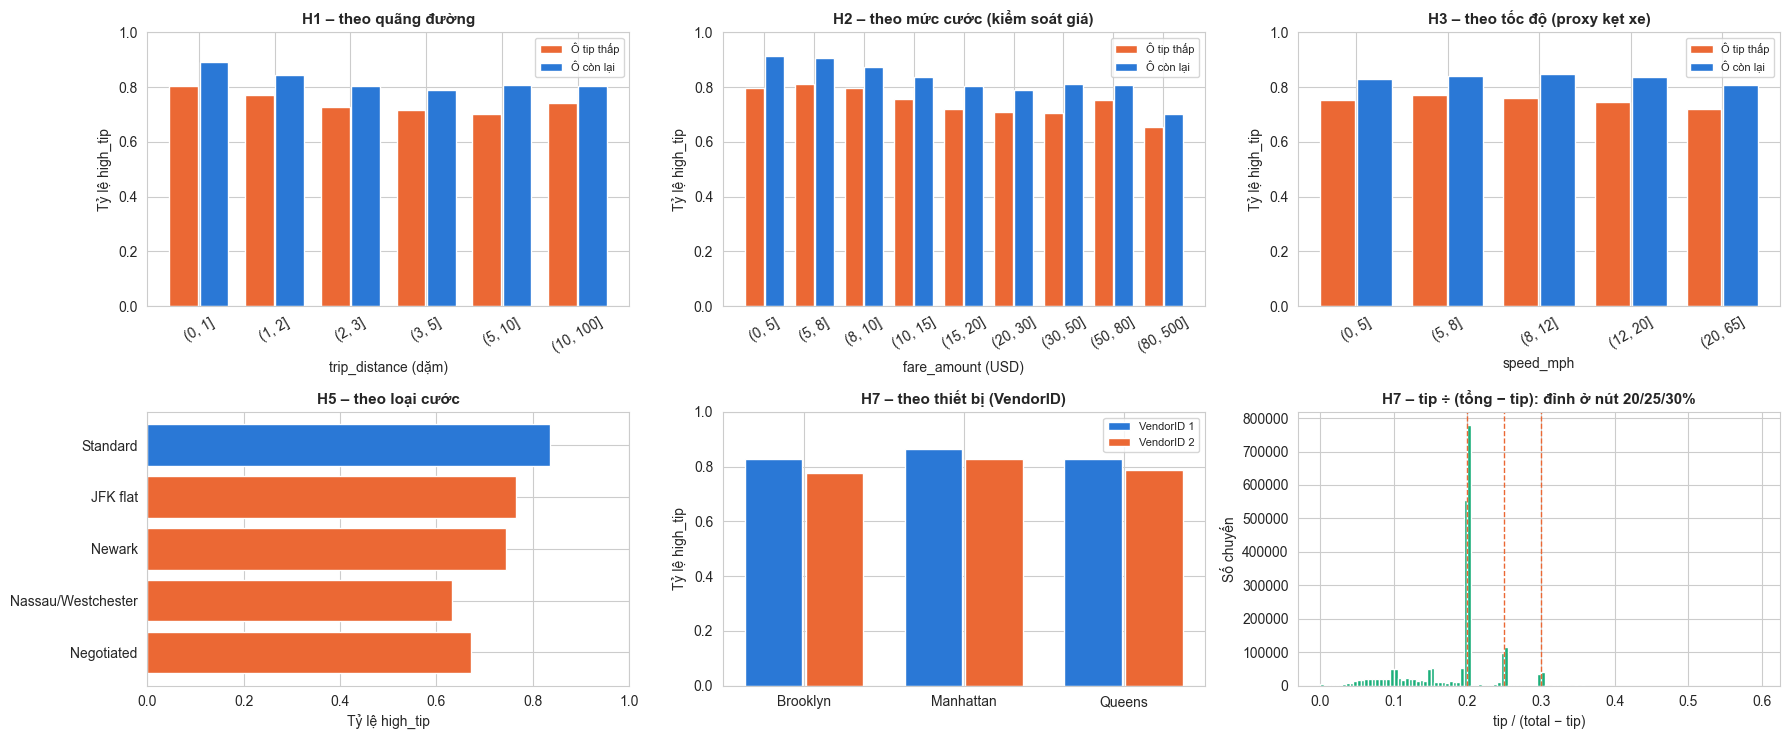

In [17]:
card_cmp = cmp_src[cmp_src["card_ok"]]
rate_by = lambda col, bins: card_cmp.groupby([pd.cut(card_cmp[col], bins), "cell_group"], observed=True)["high_tip"].mean().unstack()
h1 = rate_by("trip_distance", [0, 1, 2, 3, 5, 10, 100])
h2 = rate_by("fare_amount", FARE_BINS)
h3 = rate_by("speed_mph", [0, 5, 8, 12, 20, 65])
pv_m = cell_elig[cell_elig["slot"].str.endswith("early_morning")].pivot(index="pickup_zone", columns="slot",
                                                                        values="high_tip_rate").dropna()
h4 = pv_m["weekday|early_morning"] - pv_m["weekend|early_morning"]
RATE_NAMES = {1: "Standard", 2: "JFK flat", 3: "Newark", 4: "Nassau/Westchester", 5: "Negotiated"}
h5 = card_ok[card_ok["RatecodeID"].isin(RATE_NAMES)].groupby("RatecodeID")["high_tip"].mean().rename(RATE_NAMES)
h5_low_share = card_cmp.groupby("cell_group")["RatecodeID"].apply(lambda s: s.isin([2, 3, 4, 5]).mean())
rho_cash, p_cash = spearmanr(zone_elig["cash_share"], zone_elig["high_tip_rate"])
h7 = (card_ok[card_ok["pickup_borough"].isin(["Manhattan", "Queens", "Brooklyn"]) & card_ok["VendorID"].isin([1, 2])]
      .groupby(["pickup_borough", "VendorID"])["high_tip"].mean().unstack())
tipped = card_ok[(card_ok["tip_amount"] > 0) & (card_ok["tip_percentage"] < 0.6)]
ratio_total = tipped["tip_amount"] / (tipped["total_amount"] - tipped["tip_amount"])

hyp = pd.DataFrame([
    ["H1 chuyến ngắn", f"≤1 dặm: {h1.iloc[0]['Ô còn lại']:.3f} (cao nhất); gap trong mọi khoảng: "
                       f"{(h1['Ô còn lại'] - h1['Ô tip thấp']).min():.3f}–{(h1['Ô còn lại'] - h1['Ô tip thấp']).max():.3f}"],
    ["H2 giá đã cao", f"gap trong cùng mức cước: {(h2['Ô còn lại'] - h2['Ô tip thấp']).min():.3f}–"
                      f"{(h2['Ô còn lại'] - h2['Ô tip thấp']).max():.3f}"],
    ["H3 kẹt xe", f"0–5 mph {h3.iloc[0]['Ô còn lại']:.3f} vs 8–12 mph {h3.iloc[2]['Ô còn lại']:.3f}"],
    ["H4 khách đi làm", f"{len(h4)} zone: TB {h4.mean() * 100:+.2f} điểm %, {(h4 < 0).mean():.0%} zone thấp hơn"],
    ["H5 cước cố định", f"Standard {h5['Standard']:.3f} vs JFK flat {h5['JFK flat']:.3f} vs Negotiated {h5['Negotiated']:.3f};"
                        f" % cước 2–5: ô thấp {h5_low_share['Ô tip thấp']:.1%} vs {h5_low_share['Ô còn lại']:.1%}"],
    ["H6 tiền mặt", f"Spearman = {rho_cash:+.3f} (p = {p_cash:.1e}) trên {len(zone_elig)} zone"],
    ["H7 nút gợi ý", f"{(ratio_total.round(2) == 0.20).mean():.1%} tip đúng 20% tổng trước tip; "
                     f"{ratio_total.round(2).isin([0.20, 0.25, 0.30]).mean():.1%} đúng 20/25/30%; "
                     f"Manhattan Vendor1 {h7.loc['Manhattan', 1]:.3f} vs Vendor2 {h7.loc['Manhattan', 2]:.3f}"],
], columns=["Giả thuyết", "Bằng chứng"])
print(hyp.to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(18, 7.5))
for ax, tbl, title, xl in [(axes[0, 0], h1, "H1 – theo quãng đường", "trip_distance (dặm)"),
                           (axes[0, 1], h2, "H2 – theo mức cước (kiểm soát giá)", "fare_amount (USD)"),
                           (axes[0, 2], h3, "H3 – theo tốc độ (proxy kẹt xe)", "speed_mph")]:
    x = np.arange(len(tbl))
    for i, (gname, c) in enumerate([("Ô tip thấp", C_ORANGE), ("Ô còn lại", C_BLUE)]):
        ax.bar(x + (i - 0.5) * 0.4, tbl[gname], width=0.38, color=c, label=gname)
    ax.set_xticks(x, [str(b) for b in tbl.index], rotation=30)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.set_xlabel(xl)
    ax.set_ylabel("Tỷ lệ high_tip")
    ax.legend(fontsize=8)
axes[1, 0].barh(h5.index, h5.values, color=[C_BLUE] + [C_ORANGE] * (len(h5) - 1))
axes[1, 0].invert_yaxis()
axes[1, 0].set_xlim(0, 1)
axes[1, 0].set_title("H5 – theo loại cước")
axes[1, 0].set_xlabel("Tỷ lệ high_tip")
xx = np.arange(len(h7))
for i, (v, c) in enumerate(zip(h7.columns, [C_BLUE, C_ORANGE])):
    axes[1, 1].bar(xx + (i - 0.5) * 0.38, h7[v], width=0.36, color=c, label=f"VendorID {v}")
axes[1, 1].set_xticks(xx, h7.index)
axes[1, 1].set_ylim(0, 1)
axes[1, 1].set_title("H7 – theo thiết bị (VendorID)")
axes[1, 1].set_ylabel("Tỷ lệ high_tip")
axes[1, 1].legend(fontsize=8)
axes[1, 2].hist(ratio_total, bins=np.arange(0, 0.6, 0.005), color=C_AQUA)
for v in (0.20, 0.25, 0.30):
    axes[1, 2].axvline(v, ls="--", lw=1, color=C_ORANGE)
axes[1, 2].set_title("H7 – tip ÷ (tổng − tip): đỉnh ở nút 20/25/30%")
axes[1, 2].set_xlabel("tip / (total − tip)")
axes[1, 2].set_ylabel("Số chuyến")
plt.tight_layout()
plt.show()

| # | Kết luận | Bằng chứng chính |
|---|---|---|
| H1 chuyến ngắn | **Bác bỏ** | Chuyến ≤ 1 dặm có high_tip cao nhất (0.890); gap 0.063–0.107 ở mọi khoảng cách |
| H2 giá đã cao | **Một phần** | Giá cao giảm tip % nhưng trong cùng mức cước ô tip thấp vẫn thấp hơn 0.047–0.118 |
| H3 kẹt xe | **Không ủng hộ** | 0–5 mph 0.829 ≈ 8–12 mph 0.849; cao điểm ngày thường có high_tip cao nhất |
| H4 khách đi làm | **Ủng hộ yếu** | Sáng ngày thường thấp hơn sáng cuối tuần 1.21 điểm %, ở 62% zone; không có ID khách |
| H5 cước cố định | **Ủng hộ** | Standard 0.836 vs JFK flat 0.764 vs Negotiated 0.671; ô tip thấp có 32.7% chuyến cước 2–5 (ô khác 1.5%) |
| H6 tiền mặt | **Bác bỏ** | Spearman **+0.483** – cùng chiều, ngược giả thuyết |
| H7 nút gợi ý | **Ủng hộ mạnh** | **56.4%** tip đúng 20% tổng trước tip, 68.5% đúng 20/25/30%; Vendor1 > Vendor2 ở mọi borough |
| H8 thu nhập dân cư | **Không kiểm chứng được** | Không có dữ liệu nhân khẩu |

**Tác động:** với khách, tip thẻ = **bấm nút mặc định**; "tip thấp" là lựa chọn chủ động lệch mặc định (không tip / 10% / tự nhập). Thiết kế và minh bạch nút gợi ý là đòn bẩy tip lớn hơn mọi yếu tố khu vực/giờ. **[GIẢ THUYẾT/SUY LUẬN]** khu ăn chơi đêm cuối tuần: đi nhóm, chia tiền, đã chi nhiều — dữ liệu không kiểm chứng được.

### 4.4. Kịch bản "tip cao nhưng ít xe" — góc nhìn tài xế

| Proxy (zone × khung giờ) | Công thức | Giới hạn |
|---|---|---|
| Cầu | chuyến đón ÷ số giờ của khung trong tháng | Không thấy cầu bị bỏ lỡ |
| Cung xe rỗng tại chỗ | `flow_ratio` = chuyến **kết thúc** ÷ chuyến **bắt đầu** tại zone (< 1: xe phải tới từ nơi khác) | Không thấy xe rỗng đi ngang, hàng chờ sân bay |
| Thu nhập/giờ có khách | Σ(fare + tip thẻ) ÷ Σ thời lượng × 60 | Chưa trừ thời gian chờ/chạy rỗng |

Eligible cells: 530 | flow_ratio P25/P50/P75 = [0.8161, 1.0473, 1.4387]
Revenue per occupied hour - top 3: {'JFK Airport': 96.06, 'LaGuardia Airport': 93.16, 'Sunnyside': 92.36} | bottom 3: {'Central Harlem North': 64.18, 'Boerum Hill': 65.7, 'Fort Greene': 65.81}


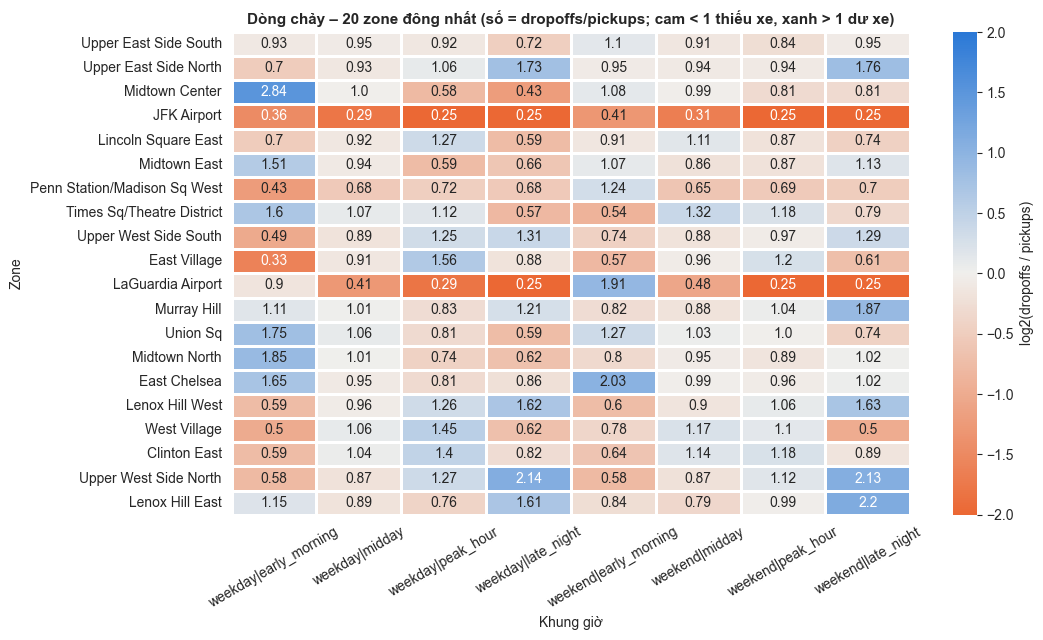

In [18]:
SLOT_HOURS = slot_label(pd.Series(pd.date_range("2026-05-01", "2026-06-01", freq="h", inclusive="left"))).value_counts()
drop_src = trips[trips["do_in_month"] & ~trips["DOLocationID"].isin(UNKNOWN_ZONE_IDS)]
dropoffs = drop_src.groupby(["DOLocationID", "dropoff_slot"]).size().rename("dropoffs")
dropoffs.index.names = ["PULocationID", "slot"]
flow = cell_tbl.set_index(["PULocationID", "slot"]).join(dropoffs).reset_index()
flow["dropoffs"] = flow["dropoffs"].fillna(0)
flow["pickups_per_hour"] = flow["trips"] / flow["slot"].map(SLOT_HOURS)
flow["flow_ratio"] = flow["dropoffs"] / flow["trips"]
flow["net_outflow_per_hour"] = (flow["trips"] - flow["dropoffs"]) / flow["slot"].map(SLOT_HOURS)
flow_elig = flow[(flow["card_ok_trips"] >= MIN_CARD_CELL) & (flow["pickups_per_hour"] >= 1)].copy()
print(f"Eligible cells: {len(flow_elig)} | flow_ratio P25/P50/P75 = "
      f"{flow_elig['flow_ratio'].quantile([.25, .5, .75]).round(4).tolist()}")
zi = zone_elig.set_index("pickup_zone")["revenue_per_occ_hour"]
print("Revenue per occupied hour - top 3:", zi.nlargest(3).round(2).to_dict(), "| bottom 3:", zi.nsmallest(3).round(2).to_dict())

top20 = zone_elig.nlargest(20, "trips")["PULocationID"]
pv = (flow[flow["PULocationID"].isin(top20)].assign(l2=lambda d: np.log2(d["flow_ratio"].clip(0.25, 4)))
      .pivot(index="pickup_zone", columns="slot", values="l2")[SLOT_ORDER])
pv = pv.loc[zone_elig.set_index("pickup_zone").loc[pv.index, "trips"].sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.heatmap(pv, cmap=DIV_CMAP, center=0, vmin=-2, vmax=2, annot=np.exp2(pv).round(2), fmt="",
            cbar_kws={"label": "log2(dropoffs / pickups)"}, ax=ax, linewidths=1, linecolor="white")
ax.set_title("Dòng chảy – 20 zone đông nhất (số = dropoffs/pickups; cam < 1 thiếu xe, xanh > 1 dư xe)")
ax.set_xlabel("Khung giờ")
ax.set_ylabel("Zone")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**[BẰNG CHỨNG TỪ DỮ LIỆU]** Dòng chảy lộ rõ mẫu hình đi làm: khu văn phòng sáng ngày thường **dư xe** (Midtown Center dropoffs/pickups **2.84**), tối **thiếu xe** (Midtown Center **0.43**); khu dân cư UES/UWS ngược lại (sáng < 1, đêm > 1). Thu nhập/giờ có khách: JFK **96.06** → Central Harlem North **64.18 USD** (chênh ~50%).

**[GIẢ THUYẾT/SUY LUẬN]** JFK/LGA có flow 0.25–0.48 ở hầu hết khung giờ vì taxi tới rỗng rồi xếp hàng ở bãi chờ (không có trong dữ liệu) → proxy **không dùng được** ở sân bay.

Targets (high_tip >= 0.8460, flow <= 0.8161): 41 (8 airport-related) | origins (flow >= 1.4387): 133
Urban targets by slot: {'weekend|early_morning': 12, 'weekday|late_night': 6, 'weekday|midday': 4, 'weekday|peak_hour': 4, 'weekend|midday': 4, 'weekday|early_morning': 2, 'weekend|late_night': 1}


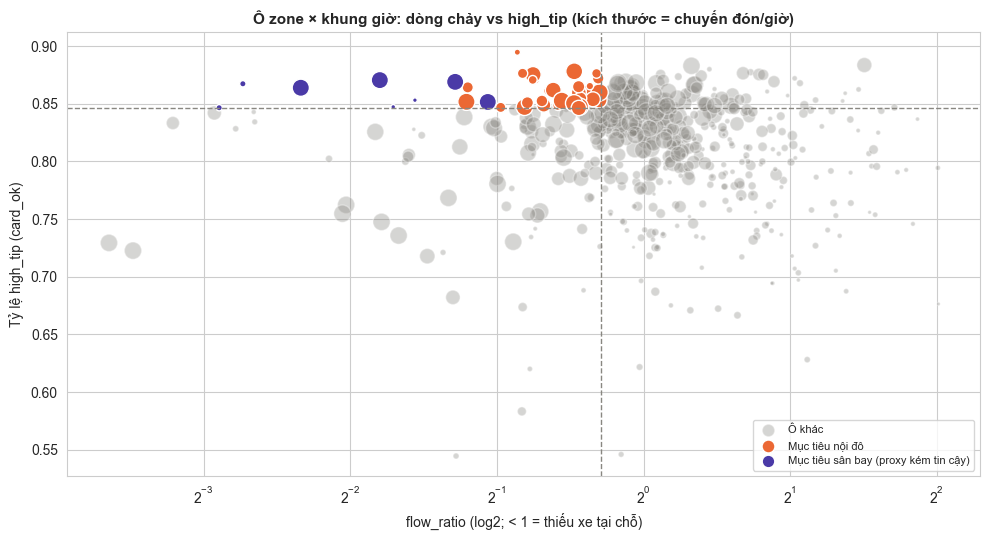

In [19]:
TIP_P75, FLOW_P25, FLOW_P75 = (flow_elig["high_tip_rate"].quantile(0.75), flow_elig["flow_ratio"].quantile(0.25),
                               flow_elig["flow_ratio"].quantile(0.75))
flow_elig["is_target"] = (flow_elig["high_tip_rate"] >= TIP_P75) & (flow_elig["flow_ratio"] <= FLOW_P25)
flow_elig["is_origin"] = flow_elig["flow_ratio"] >= FLOW_P75
targets = flow_elig[flow_elig["is_target"]].copy()
targets["airport_related"] = (targets["airport_share"] >= 0.5) | (targets["airport_fee_share"] >= 0.5)
print(f"Targets (high_tip >= {TIP_P75:.4f}, flow <= {FLOW_P25:.4f}): {len(targets)} "
      f"({int(targets['airport_related'].sum())} airport-related) | origins (flow >= {FLOW_P75:.4f}): {int(flow_elig['is_origin'].sum())}")
print("Urban targets by slot:", targets.loc[~targets["airport_related"], "slot"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(10, 5.5))
rest = flow_elig[~flow_elig["is_target"]]
ax.scatter(rest["flow_ratio"], rest["high_tip_rate"], s=rest["pickups_per_hour"].clip(upper=150) + 4,
           color=C_GREY, alpha=0.35, edgecolor="white", label="Ô khác")
for is_ap, c, lab in [(False, C_ORANGE, "Mục tiêu nội đô"), (True, C_VIOLET, "Mục tiêu sân bay (proxy kém tin cậy)")]:
    s = targets[targets["airport_related"] == is_ap]
    ax.scatter(s["flow_ratio"], s["high_tip_rate"], s=s["pickups_per_hour"].clip(upper=150) + 4, color=c,
               edgecolor="white", label=lab)
ax.axvline(FLOW_P25, ls="--", lw=1, color=C_GREY)
ax.axhline(TIP_P75, ls="--", lw=1, color=C_GREY)
ax.set_xscale("log", base=2)
ax.set_title("Ô zone × khung giờ: dòng chảy vs high_tip (kích thước = chuyến đón/giờ)")
ax.set_xlabel("flow_ratio (log2; < 1 = thiếu xe tại chỗ)")
ax.set_ylabel("Tỷ lệ high_tip (card_ok)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**[BẰNG CHỨNG TỪ DỮ LIỆU]** **41** ô "tip cao – cung thấp" (high_tip ≥ 0.8460, flow ≤ 0.8161): **8 ô sân bay** (LaGuardia + East Elmhurst – zone sát LGA có 81–86% chuyến thu `Airport_fee`) và **33 ô nội đô**, nhiều nhất là **sáng sớm cuối tuần ở UES/UWS (12 ô)** và **đêm ngày thường ở Midtown (6 ô)**.

**[GIẢ ĐỊNH KỊCH BẢN] Tác động nếu tài xế dịch chuyển:** $\text{income}_c = 60 \cdot R_c / (D_c + W_c)$, $R_c, D_c$ = doanh thu & thời lượng TB/chuyến (**đo từ dữ liệu**); thời gian chờ $W_c = W_0 \cdot \text{flow\_ratio}_c$ (2–45′), $W_0 \in \{5, 10, 15\}$; chạy rỗng một lần $T \in \{10, 20, 30\}$′/ca 4h; ô xuất phát = TB các ô dư xe cùng khung giờ. Hệ thống: ô mục tiêu nội đô hấp thụ thêm α ∈ {5, 10, 20}% chuyến (cận trên).

Urban targets: 33 | median gain (W0=10, deadhead=20) = 9.49 USD/h
Without wait assumption: median occupied-hour gap = 0.01 USD/h, positive in 52%
Sensitivity (median USD/h):
 deadhead (min)      10      20     30
W0 (min)                             
5               8.1100  5.2400 2.6100
10             11.7700  9.4900 7.4200
15             13.1100 11.2800 9.4500

System impact (upper bound):
 alpha  extra_trips_month  extra_revenue_usd_month  share_of_month_revenue
   5%        16,810.5500             348,081.9700                  0.0037
  10%        33,621.1000             696,163.9400                  0.0073
  20%        67,242.2000           1,392,327.8800                  0.0147


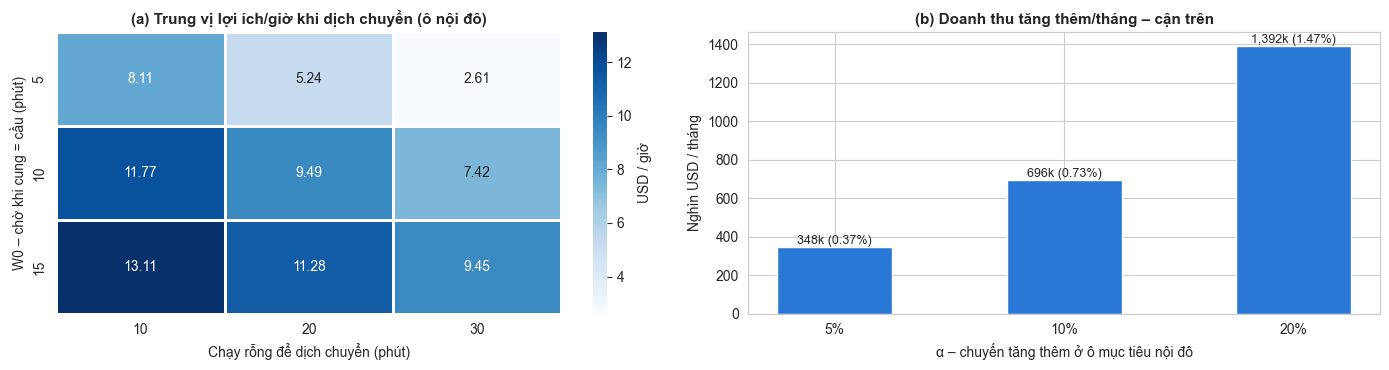

In [20]:
hourly_income = lambda rev, dur, flow_r, w0: 60 * rev / (dur + np.clip(w0 * flow_r, 2, 45))
w_avg = lambda d, c: np.average(d[c], weights=d["trips"])
origin = (flow_elig[flow_elig["is_origin"]].groupby("slot")
          .apply(lambda d: pd.Series({c: w_avg(d, c) for c in ["revenue_per_trip", "avg_duration", "flow_ratio"]}))
          .add_prefix("o_"))
urban = targets[~targets["airport_related"]].merge(origin, left_on="slot", right_index=True)


def gain(w0, dh, df=urban):
    return (hourly_income(df["revenue_per_trip"], df["avg_duration"], df["flow_ratio"], w0) * (1 - dh / 240)
            - hourly_income(df["o_revenue_per_trip"], df["o_avg_duration"], df["o_flow_ratio"], w0))


urban["gain_per_hour"] = gain(10, 20)
sens = pd.DataFrame({dh: {w0: np.median(gain(w0, dh)) for w0 in (5, 10, 15)} for dh in (10, 20, 30)})
sens.index.name, sens.columns.name = "W0 (min)", "deadhead (min)"
occ_gap = 60 * urban["revenue_per_trip"] / urban["avg_duration"] - 60 * urban["o_revenue_per_trip"] / urban["o_avg_duration"]
system = pd.DataFrame([{"alpha": f"{a:.0%}", "extra_trips_month": (a * urban["trips"]).sum(),
                        "extra_revenue_usd_month": (a * urban["trips"] * urban["revenue_per_trip"]).sum()}
                       for a in (0.05, 0.10, 0.20)])
system["share_of_month_revenue"] = system["extra_revenue_usd_month"] / zone_src["revenue"].sum()
print(f"Urban targets: {len(urban)} | median gain (W0=10, deadhead=20) = {urban['gain_per_hour'].median():.2f} USD/h")
print(f"Without wait assumption: median occupied-hour gap = {occ_gap.median():.2f} USD/h, positive in {(occ_gap > 0).mean():.0%}")
print("Sensitivity (median USD/h):\n", sens.round(2).to_string())
print("\nSystem impact (upper bound):\n", system.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
sns.heatmap(sens, annot=True, fmt=".2f", cmap="Blues", ax=axes[0], cbar_kws={"label": "USD / giờ"},
            linewidths=2, linecolor="white")
axes[0].set_title("(a) Trung vị lợi ích/giờ khi dịch chuyển (ô nội đô)")
axes[0].set_xlabel("Chạy rỗng để dịch chuyển (phút)")
axes[0].set_ylabel("W0 – chờ khi cung = cầu (phút)")
axes[1].bar(system["alpha"], system["extra_revenue_usd_month"] / 1000, color=C_BLUE, width=0.5)
for i, (v, s) in enumerate(zip(system["extra_revenue_usd_month"] / 1000, system["share_of_month_revenue"])):
    axes[1].text(i, v, f"{v:,.0f}k ({s:.2%})", ha="center", va="bottom", fontsize=9)
axes[1].set_title("(b) Doanh thu tăng thêm/tháng – cận trên")
axes[1].set_xlabel("α – chuyến tăng thêm ở ô mục tiêu nội đô")
axes[1].set_ylabel("Nghìn USD / tháng")
plt.tight_layout()
plt.show()

**Insight:** dồn về ô nội đô "tip cao – ít xe" có lợi **chỉ nhờ chờ khách ít hơn**; bản thân chuyến ở đó không đắt hơn.

**[BẰNG CHỨNG TỪ DỮ LIỆU + GIẢ ĐỊNH]**
- Trung vị **+9.49 USD/giờ** (W0 = 10′, chạy rỗng 20′); độ nhạy **+2.61 → +13.11 USD/giờ**.
- Bỏ giả định chờ: chênh lệch chỉ **+0.01 USD/giờ**, dương ở 52% ô.
- Hệ thống (cận trên): +5/10/20% chuyến ở ô mục tiêu → **+348k / 696k / 1.39 triệu USD/tháng = 0.37 / 0.73 / 1.47%** doanh thu tháng.

**Tác động:** tài xế — lợi ích thực nhưng phụ thuộc thời gian chờ thật; nền tảng — đòn bẩy ≤ 1.5% doanh thu → thí điểm nhỏ, có A/B test.

### 4.5. Đề xuất hành động & Deployment

In [21]:
tm = test_meta[test_meta["card_ok"] & test_meta["pu_in_month"] & ~test_meta["PULocationID"].isin(UNKNOWN_ZONE_IDS)]
calib = tm.groupby(CELL).agg(n=("high_tip", "size"), actual=("high_tip", "mean"), predicted=("p_hgb", "mean"))
calib = calib[calib["n"] >= 50]
print(f"DM1 aggregated by cell ({len(calib)} test cells): Spearman = {spearmanr(calib['predicted'], calib['actual'])[0]:.4f}, "
      f"MAE = {(calib['predicted'] - calib['actual']).abs().mean():.4f}")
reco = (urban[urban["gain_per_hour"] > 0].sort_values("gain_per_hour", ascending=False).groupby("slot").head(1)
        [["slot", "pickup_zone", "high_tip_rate", "avg_tip_usd", "flow_ratio", "net_outflow_per_hour", "gain_per_hour"]])
print("\nBest urban cell per slot (driver / zone-bonus candidates):\n", reco.round(2).to_string(index=False))

DM1 aggregated by cell (442 test cells): Spearman = 0.6201, MAE = 0.0236

Best urban cell per slot (driver / zone-bonus candidates):
                  slot                  pickup_zone  high_tip_rate  avg_tip_usd  flow_ratio  net_outflow_per_hour  gain_per_hour
   weekday|late_night               Midtown Center         0.8500       3.8900      0.4300               93.1800        27.3400
weekend|early_morning               Yorkville East         0.8600       3.5100      0.4400               34.7200        15.8100
   weekend|late_night          Lincoln Square East         0.8600       3.6500      0.7400               29.0700        13.8800
weekday|early_morning      Greenwich Village North         0.8600       3.5900      0.7300               14.0600        12.8400
    weekday|peak_hour Penn Station/Madison Sq West         0.8500       4.4800      0.7200               56.7300        12.0600
       weekend|midday               Yorkville East         0.8500       3.3600      0.7400        

**[BẰNG CHỨNG TỪ DỮ LIỆU]** Gộp theo ô, DM1 dự đoán đúng tỷ lệ high_tip (442 ô, Spearman **0.62**, MAE **2.4 điểm %**) — nhưng high_tip không phải KPI tài xế (4.1.5).

| Đối tượng | Hành động | Căn cứ |
|---|---|---|
| **Nền tảng** | Không dùng DM1 gợi ý tài xế; thay bằng **bảng KPI lịch sử theo ô** (thu nhập/giờ, tip USD) + A/B test | DM1 −2.66; lịch sử +7.00 → +24.60 USD/giờ |
| | Gắn cờ RatecodeID = 99 trước mọi báo cáo tip theo khu vực | Né sai 2,785 chuyến/ngày |
| | Thưởng khu vực thí điểm: **Midtown Center đêm ngày thường** (93.2 chuyến/giờ thiếu xe tại chỗ), **Penn Station cao điểm** (56.7), **Yorkville East sáng cuối tuần** (34.7) | Bảng trên |
| | Lịch điều phối riêng cho cụm dài/sân bay (DM2 k=6); điều phối xe rỗng ngược dòng chảy sáng/tối | 4.1.6, 4.4 |
| **Tài xế** | Đêm ngày thường: Midtown Center (+27.34 USD/giờ\*) · sáng sớm cuối tuần: Yorkville East (+15.81\*) · sáng sớm ngày thường: Greenwich Village North (+12.84\*) · cao điểm: Penn Station (+12.06\*) | \*giả định W0 = 10′ |
| | Chọn khu theo tip USD/thu nhập giờ: sân bay tip 12.88 USD vs 3.4–4.2 USD lõi Manhattan; tránh kỳ vọng tip ở khu ăn chơi đêm cuối tuần | 4.2, 4.3 |
| **Khách** | Minh bạch nút tip tính % trên tổng tiền gồm phụ phí; đặt xe sớm ở khung thiếu xe (UES sáng cuối tuần, Midtown đêm) | H7, 4.4 |

| Deployment | Dùng cho | Không dùng cho | Theo dõi |
|---|---|---|---|
| **DM1** | Chỉ theo dõi tỷ lệ tip theo ô, sau khi lặp lại vòng CRISP-DM | Gợi ý tài xế, dự đoán từng chuyến, rút xe khỏi khu vực | Tỷ lệ RatecodeID = 99; phân bố tip/(tổng − tip); calibration theo ô |
| **DM2** | Lịch điều phối ngày thường / cuối tuần / sân bay | Dự đoán tip, định giá | Tỷ trọng cụm theo tuần (drift); USD/giờ có khách theo cụm |

### 4.6. Review quy trình & bước tiếp theo

In [22]:
dm1_bt = backtest.loc["DM1: top 20% P(high_tip)", "rev_per_occ_hour"] - sq["rev_per_occ_hour"]
checklist = pd.DataFrame([
    ["DM1", "AUC vượt Dummy & baseline", f"HGB {results_dm1.loc[2, 'AUC']:.4f} | LogReg {results_dm1.loc[1, 'AUC']:.4f} | Dummy 0.5", "Đạt"],
    ["DM1", "AUC khi loại artifact RatecodeID=99", f"{model_quality.loc['Loại RatecodeID=99', 'AUC']:.4f}", "Cần lưu ý"],
    ["DM1", "Tạo giá trị cho tài xế (backtest)", f"{dm1_bt:+.2f} USD/giờ có khách", "Đạt" if dm1_bt > 0 else "Không đạt"],
    ["DM2", "Silhouette > 0.3", f"k=5 {scan.loc[5, 'silhouette_best']:.4f} | k=6 {scan.loc[6, 'silhouette_best']:.4f}",
     "Đạt" if scan.loc[[5, 6], "silhouette_best"].max() > 0.3 else "Không đạt"],
    ["DM2", "Cụm khác nhau về giá trị kinh tế", f"cụm sân bay k=6: {prof_k6.loc[ap, 'share_trips']:.1%} chuyến – "
                                                f"{prof_k6.loc[ap, 'share_revenue']:.1%} doanh thu", "Đạt"],
    ["Business", "Khuyến nghị hành động có số liệu", f"{len(urban)} ô nội đô mục tiêu, backtest, tác động khách", "Đạt (proxy)"],
], columns=["Bài toán", "Tiêu chí", "Kết quả", "Đánh giá"])
print(checklist.to_string(index=False))

Bài toán                            Tiêu chí                                        Kết quả    Đánh giá
     DM1           AUC vượt Dummy & baseline         HGB 0.7164 | LogReg 0.6825 | Dummy 0.5         Đạt
     DM1 AUC khi loại artifact RatecodeID=99                                         0.6226   Cần lưu ý
     DM1   Tạo giá trị cho tài xế (backtest)                         -2.66 USD/giờ có khách   Không đạt
     DM2                    Silhouette > 0.3                        k=5 0.2054 | k=6 0.2416   Không đạt
     DM2    Cụm khác nhau về giá trị kinh tế cụm sân bay k=6: 8.5% chuyến – 23.9% doanh thu         Đạt
Business    Khuyến nghị hành động có số liệu 33 ô nội đô mục tiêu, backtest, tác động khách Đạt (proxy)


| | Điểm mạnh | Điểm yếu / còn tồn tại |
|---|---|---|
| **Dữ liệu** | 3.9 triệu chuyến; pipeline tái tạo trùng khớp 100% | Không có tip tiền mặt; 877,060 chuyến (22.6%) không báo thanh toán; artifact RatecodeID = 99 lọt qua Preparation; 1 tháng; không có ID xe/khách |
| **DM1** | Vượt Dummy/LogReg (AUC 0.7164) | AUC 0.6226 khi loại artifact; nhãn bị chi phối bởi phụ phí/nút bấm; ngược KPI tài xế; chỉ có borough |
| **DM2** | Cụm khác rõ về doanh thu/giờ; k=6 tách được sân bay | Silhouette 0.2054 < 0.3; không phân biệt tip |
| **Phân tích** | Backtest, tác động khách, kịch bản có độ nhạy; tách bằng chứng/giả thuyết | Proxy cung sai ở sân bay; lợi ích dịch chuyển phụ thuộc giả định chờ |

**Hướng cải thiện:** (1) Preparation: gắn cờ chuyến thẻ RatecodeID = 99; (2) đổi nhãn/KPI: tip % trên tổng trước tip, hoặc hồi quy **tip USD / thu nhập giờ**; (3) thêm `PULocationID`/`DOLocationID`, `RatecodeID`, `VendorID`, cờ `Airport_fee`; (4) DM2 k=6, dùng zone thay borough; (5) thêm nhiều tháng, Census theo zone (H8), dữ liệu bãi chờ sân bay, FHV; (6) lưu model bằng `joblib`.

**Quyết định:** **DM2 → Deployment thí điểm** · **bảng KPI zone × khung giờ → thí điểm có A/B test** · **DM1 → lặp lại vòng CRISP-DM** (Preparation → Modeling), đánh giá lại bằng backtest 4.1.5.